# 07. 모델링과 검정 — 전체 11단계 중 7단계

작업하며 주고받은 글(내가 셀마다 적은 칸과 클로드의 답변)은 빼고 코드 · 결과 · 결정만 남긴 판이다. 진행 방식은 README 「진행 방식」에 있다.

**이 단계에서 한 일과 정한 것** — 2025년으로 한 번 채점해, 모델 넷 모두 기준선보다 잘 맞힌 것을 확인했다. 낮에는 LNG 발전량을 실제보다 많게 예측했고(태양광 설비가 늘어서), 30도 넘는 시각과 토요일에 크게 틀렸다. 달마다 모델이 LNG를 더 많게 또는 더 적게 예측한 것은 12달 가운데 10달이 원전 · 석탄 발전량이 모델 예측과 달랐던 것과 같은 쪽이었다. 채점을 본 뒤 모델을 고치면 그 점수가 실제보다 좋게 나와서, 모델은 고치지 않고 틀린 곳을 한계로 적었다.

### 말 뜻 — 표를 읽을 때 쓰는 말

| 말 | 뜻 |
|---|---|
| 실제 | 그해(주로 2026년)에 실제로 발전한 양 · 실제 값입니다. 전력거래소 자료 그대로입니다 |
| 모델 예측 | 2023 ~ 2025년을 배운 모델이 그때의 날씨 · 시각 · 날 종류를 보고 예측한 양입니다. 9단계까지는 「평소라면」이라고 불렀습니다 |
| 실제 − 모델 예측 | 발전량 표의 숫자입니다. + 면 실제가 모델 예측보다 많았다, − 면 적었다는 뜻입니다 |
| 평소 해 | 2023 · 2024 · 2025년입니다. 「평소」는 이 세 해만 가리킵니다 |
| 평소 범위 | 평소 해에 모델 예측이 한 달 평균으로 가장 크게 틀린 크기(±2,177 MWh)입니다. 모델이 예측해 본 2024 · 2025년으로 냈습니다. 2026년의 차이가 이 안이면 「달랐다고 말할 근거가 없다」로 읽습니다 |
| 세 해 평균 | 2023 ~ 2025년 같은 달 값의 평균입니다. 모델 없이 계산한 것으로, 10단계 가격 표(2-가 · 2-라)에서만 씁니다 |

앞 단계 글에서 발전량을 두고 쓴 「평소보다 많았다 · 적었다」는 「모델 예측보다 많았다 · 적었다」로 읽습니다.

In [369]:
# 7단계 모델링과 검정 · 준비 ①
import os                                      # 폴더와 파일 경로를 다루는 기본 모듈
import numpy as np                             # 숫자 계산
import pandas as pd                            # 표(데이터프레임)를 다루는 라이브러리
import matplotlib.pyplot as plt                # 그림을 그리는 라이브러리
import sklearn                                 # 판 번호를 적어 두려고 부른다
from scipy import stats                        # 정규분포와 검정 — 1-다·1-라의 잔차 가정
from IPython.display import display            # 표를 글자가 아니라 격자로 그린다
from sklearn.linear_model import LinearRegression                                   # 선형회귀 — 6단계와 같다
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor   # 트리 계열 둘 — 6단계와 같다
plt.rcParams["font.family"] = "AppleGothic"    # 맥에서 그림 속 한글이 깨지지 않게
plt.rcParams["axes.unicode_minus"] = False     # 그림의 마이너스 부호가 깨지지 않게
pd.set_option("display.max_columns", 50)       # 열이 많아도 생략하지 않고 다 보이게

ROOT = os.getcwd()                             # 지금 폴더(보통 notebooks/)에서 시작해서
while not os.path.isdir(os.path.join(ROOT, "data")) and ROOT != os.path.dirname(ROOT):
    ROOT = os.path.dirname(ROOT)               # data 폴더가 보일 때까지 위로 = 프로젝트 루트
HOT = os.path.join(ROOT, "data", "hot")        # 5단계가 만들어 둔 파일이 있는 폴더

print("프로젝트 루트:", ROOT)                    # 경로가 맞는지만 확인한다
print("scikit-learn 판:", sklearn.__version__)   # 그래디언트 부스팅은 판이 다르면 소수점 아래 넷째 숫자가 달라질 수 있어 적어 둔다(6단계 물음 2)

프로젝트 루트: /Users/kimchangju/vs코드 /개인 프로젝트/lng-project
scikit-learn 판: 1.9.0


In [370]:
# 7단계 모델링과 검정 · 준비 ②
tbl = pd.read_csv(os.path.join(HOT, "features_2023_2024_2025.csv"), encoding="utf-8-sig")  # 5단계 「저장」 셀이 만든 표 — 6단계와 같은 파일
tbl["ts"] = pd.to_datetime(tbl["ts"])            # 글자로 저장된 시각을 다시 시각 자료형으로
tbl = tbl.set_index("ts").sort_index()           # 시각을 줄 이름으로 두고 시간 순서대로 놓는다
tbl.loc[tbl["year"] == 2025, "lng_mwh"] = np.nan   # 누수를 막는다 — 2025년 LNG는 읽자마자 비우고, 물음 2의 채점 셀 하나만 다시 읽는다

전체 = tbl.dropna(subset=["3시간 전 기온"])          # 3시간 전 기온이 빈 9시각(2023-01-01 · 2024-03-01 · 2024-09-01의 0~2시)은 뺀다 — 6단계와 같다
배움 = 전체["year"].isin([2023, 2024])             # 모델이 배우는 두 해
y = 전체["lng_mwh"]                                # 맞힐 값 — 그 시각의 LNG 발전량(MWh). 2025년은 비어 있다

def 선형열(d):                                     # 선형회귀에 넣는 열 — 6단계 닫는 칸 ② 「입력 — 선형회귀」, 67열
    시각열 = pd.get_dummies(d["hour24"].astype(str), prefix="시", drop_first=True).astype(float)   # 1~23시 0/1 열 — 0시가 기준
    월열 = pd.get_dummies(d["month"].astype(str), prefix="월", drop_first=True).astype(float)      # 2~12월 0/1 열 — 1월이 기준
    날열 = pd.get_dummies(d["날 종류"], prefix="날").astype(float).drop(columns="날_월")            # 화~금·토·일·공휴일·명절 — 월요일이 기준
    쉬는날 = d["날 종류"].isin(["토", "일", "공휴일", "명절"]).astype(float)                         # 쉬는 날이면 1
    쉬는날시간대 = (시각열 - 1 / 24).mul(쉬는날, axis=0)                                            # 5단계 물음 7 — 시간대 열의 평균(1/24)을 빼고 쉬는 날과 곱한다
    쉬는날시간대.columns = [f"쉬는 날×{c[2:]}시" for c in 시각열.columns]                            # 열 이름 — 「쉬는 날×9시」
    기상 = pd.DataFrame({"16도보다 추운 만큼": d["16도보다 추운 만큼"],                               # 5단계 물음 1 — 16·24도
                         "24도보다 더운 만큼": d["24도보다 더운 만큼"],
                         "3시간 동안 바뀐 만큼 (추운 쪽)": d["16도보다 추운 만큼"] - d["3시간 전 16도보다 추운 만큼"],   # 6단계 4-라 — 지금 값 − 3시간 전 값
                         "3시간 동안 바뀐 만큼 (더운 쪽)": d["24도보다 더운 만큼"] - d["3시간 전 24도보다 더운 만큼"],
                         "일사": d["icsr"]})                                                       # 5단계 물음 3 — 일사 한 열
    return pd.concat([시각열, 월열, 날열, 기상, 쉬는날시간대], axis=1)

기온두열 = ["16도보다 추운 만큼", "24도보다 더운 만큼"]                                               # 선형회귀의 지금 기온 두 열
def 시간대기온열(d):                                # 기온 × 시간대 선형회귀 — 기온 두 열 대신 시간대마다 나눈 48열, 113열(6단계 물음 6)
    나눔 = pd.DataFrame({f"{c}×{h}시": d[c] * (d["hour24"] == h) for c in 기온두열 for h in range(24)}, index=d.index)   # 그 시간대일 때만 값, 아니면 0
    return 선형열(d).drop(columns=기온두열).join(나눔)

def 트리열(d):                                     # 트리 계열에 넣는 열 — 숫자 그대로 7열(6단계 닫는 칸 ② 「입력 — 트리 계열」)
    return d[["hour24", "month", "icsr", "ta", "dow", "is_holiday", "명절"]]

입력 = {"선형회귀": 선형열(전체), "기온 × 시간대 선형회귀": 시간대기온열(전체), "트리 계열": 트리열(전체)}   # 세 해의 열을 한 번에 만든다 — 해마다 같은 열이 되게

print(f"표 모양: {len(tbl):,}행 · {tbl.shape[1] + 1}열 — 6단계가 읽은 것과 같은 파일")
쓰는곳 = {2023: "배우는 해", 2024: "배우는 해", 2025: "물음 2에서 한 번 채점 — 그 전까지 LNG는 비어 있다"}
display(pd.DataFrame({"시각 수": 전체.groupby("year").size(), "LNG가 있는 시각": y.notna().groupby(전체["year"]).sum(),
                      "이 노트북에서": pd.Series(쓰는곳)}).rename_axis("해"))

표 모양: 25,536행 · 25열 — 6단계가 읽은 것과 같은 파일


,시각 수,LNG가 있는 시각,이 노트북에서
해,,,
2023,8757,8757,배우는 해
2024,8010,8010,배우는 해
2025,8760,0,물음 2에서 한 번 채점 — 그 전까지 LNG는 비어 있다


# 물음 1 — 채점하기 전에, 6단계에서 정한 대로 모델 넷을 만들었나, 배운 결과가 회귀의 가정을 지키나

> **결정** — 6단계에서 정한 대로 만들었고(결정계수 같음 · VIF 10 아래), 잔차는 독립성이 크게 깨졌다. 모델과 입력은 그대로 두고 물음 2(2025년 채점)로 간다

## 1-가 — 6단계에서 정한 모델 넷을 이 노트북에서 다시 만들면 6단계와 같은 결정계수가 나오나

**무엇을 보는 셀인가.** 6단계와 같은 연습(2023년으로 배워 2024년 맞히기)을 이 노트북 코드로 다시 해서, 모델마다 넣는 열 수와 결정계수를 6단계에서 나온 값과 나란히 놓습니다([표 1]).

In [371]:
# 7단계 모델링과 검정 · 1-가
모델들 = {"선형회귀": (lambda: LinearRegression(), "선형회귀"),                                    # 6단계 닫는 칸 ② 「시험할 모델」 넷
          "기온 × 시간대 선형회귀": (lambda: LinearRegression(), "기온 × 시간대 선형회귀"),
          "랜덤포레스트": (lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=1, max_features=0.5,
                                                      n_jobs=-1, random_state=0), "트리 계열"),       # 6단계 물음 6에서 2024년으로 고른 설정
          "그래디언트 부스팅": (lambda: HistGradientBoostingRegressor(early_stopping=False, random_state=0), "트리 계열")}   # 설정은 그대로
육단계 = {"선형회귀": (0.7524, "4-라 [표 2]"), "기온 × 시간대 선형회귀": (0.7679, "6-나 [표 1]"),         # 6단계에서 2023년으로 배워 2024년을 맞힌 결정계수
          "랜덤포레스트": (0.7701, "6-바 [표 2] 고른 설정"), "그래디언트 부스팅": (0.7807, "6-바 [표 2] 지금 설정")}

연습배움 = 전체["year"] == 2023                                                               # 6단계와 같은 연습 — 2023년으로 배워
연습맞힘 = 전체["year"] == 2024                                                               # 2024년을 맞힌다
줄 = []
for 이름, (만들기, 열) in 모델들.items():
    X = 입력[열]
    값 = 만들기().fit(X[연습배움], y[연습배움]).score(X[연습맞힘], y[연습맞힘])                  # 2024년을 맞힌 결정계수
    전값, 칸 = 육단계[이름]
    줄.append({"모델": 이름, "넣는 열 수": X.shape[1], "6단계 결정계수": f"{전값:.4f}", "6단계에서 나온 칸": 칸,
               "이 노트북 결정계수": f"{값:.4f}", "같은가": "같다" if f"{값:.4f}" == f"{전값:.4f}" else "다르다"})

print(f"2023년 {int(연습배움.sum()):,}시각으로 배워 2024년 {int(연습맞힘.sum()):,}시각을 맞혔다 — 6단계에서 하던 연습 그대로")
print("[표 1] 6단계에서 정한 모델 넷을 이 노트북 코드로 다시 만들면, 2024년을 맞힌 결정계수가 6단계와 같은가")
display(pd.DataFrame(줄).set_index("모델"))

2023년 8,757시각으로 배워 2024년 8,010시각을 맞혔다 — 6단계에서 하던 연습 그대로
[표 1] 6단계에서 정한 모델 넷을 이 노트북 코드로 다시 만들면, 2024년을 맞힌 결정계수가 6단계와 같은가


,넣는 열 수,6단계 결정계수,6단계에서 나온 칸,이 노트북 결정계수,같은가
모델,,,,,
선형회귀,67,0.7524,4-라 [표 2],0.7524,같다
기온 × 시간대 선형회귀,113,0.7679,6-나 [표 1],0.7679,같다
랜덤포레스트,7,0.7701,6-바 [표 2] 고른 설정,0.7701,같다
그래디언트 부스팅,7,0.7807,6-바 [표 2] 지금 설정,0.7807,같다


## 1-나 — 선형회귀 둘에 넣는 열끼리 겹치나(VIF)

**무엇을 보는 셀인가.** 배우는 두 해의 입력으로 열마다 VIF를 계산해서, 모델마다 10을 넘는 열 수([표 1])와 VIF가 가장 큰 열 다섯([표 2])을 놓습니다. 열마다 회귀를 한 번씩 돌려서 20초쯤 걸립니다.

In [372]:
# 7단계 모델링과 검정 · 1-나
def VIF값(X, 열):                                                                   # 그 열을 나머지 열로 맞힌 R²로 계산한다 — VIF = 1 / (1 − R²) (6단계 4-라와 같다)
    나머지 = X.drop(columns=열)
    return 1 / (1 - LinearRegression().fit(나머지, X[열]).score(나머지, X[열]))

선형둘 = ["선형회귀", "기온 × 시간대 선형회귀"]                                          # VIF는 기울기를 배우는 선형회귀 둘만 센다 — 트리에는 기울기가 없다(6단계 4-다 답변 5)
VIF = {이름: pd.Series({c: VIF값(입력[이름][배움], c) for c in 입력[이름].columns}) for 이름 in 선형둘}   # 배우는 두 해(2023·2024년)의 입력으로 계산
표1 = pd.DataFrame({"열 수": {이름: len(v) for 이름, v in VIF.items()},
                    "VIF가 10을 넘는 열 수": {이름: int((v > 10).sum()) for 이름, v in VIF.items()}}).rename_axis("모델")
표2 = pd.concat({이름: v.sort_values(ascending=False).head(5).round(1).rename_axis("열").reset_index(name="VIF")
                 for 이름, v in VIF.items()}, axis=1)
표2.index = pd.RangeIndex(1, 6, name="큰 순서")

print(f"배우는 두 해(2023·2024년) {int(배움.sum()):,}시각의 입력으로 계산했다 — VIF가 10을 넘으면 다른 열과 겹친다고 본다(지침 7단계 칸)")
print("[표 1] 모델마다 열 수와, 그 가운데 VIF가 10을 넘는 열 수")
display(표1)
print("[표 2] 모델마다 VIF가 가장 큰 열 다섯")
display(표2)

배우는 두 해(2023·2024년) 16,767시각의 입력으로 계산했다 — VIF가 10을 넘으면 다른 열과 겹친다고 본다(지침 7단계 칸)
[표 1] 모델마다 열 수와, 그 가운데 VIF가 10을 넘는 열 수


,열 수,VIF가 10을 넘는 열 수
모델,,
선형회귀,67,0
기온 × 시간대 선형회귀,113,0


[표 2] 모델마다 VIF가 가장 큰 열 다섯


선형회귀      기온 × 시간대 선형회귀     
                열  VIF             열  VIF
큰 순서                                     
1     16도보다 추운 만큼  4.7          시_13  5.9
2             월_7  4.5          시_14  5.8
3             월_9  4.2          시_12  5.8
4             월_6  4.1          시_11  5.7
5              일사  4.1          시_15  5.6

## 1-다 — 잔차 가정 셋을 그림으로 보기: 등분산성 · 정규성 · 독립성

**무엇을 보는 셀인가.** 선형회귀 둘을 2023·2024년으로 배우고, 같은 두 해를 다시 맞힌 잔차(실제 − 예측)를 그림 셋으로 봅니다 — 예측값과 잔차(등분산성), Q-Q 그림(정규성), 몇 시간 떨어진 잔차끼리의 상관(독립성). 위 줄이 선형회귀, 아래 줄이 기온 × 시간대 선형회귀입니다.

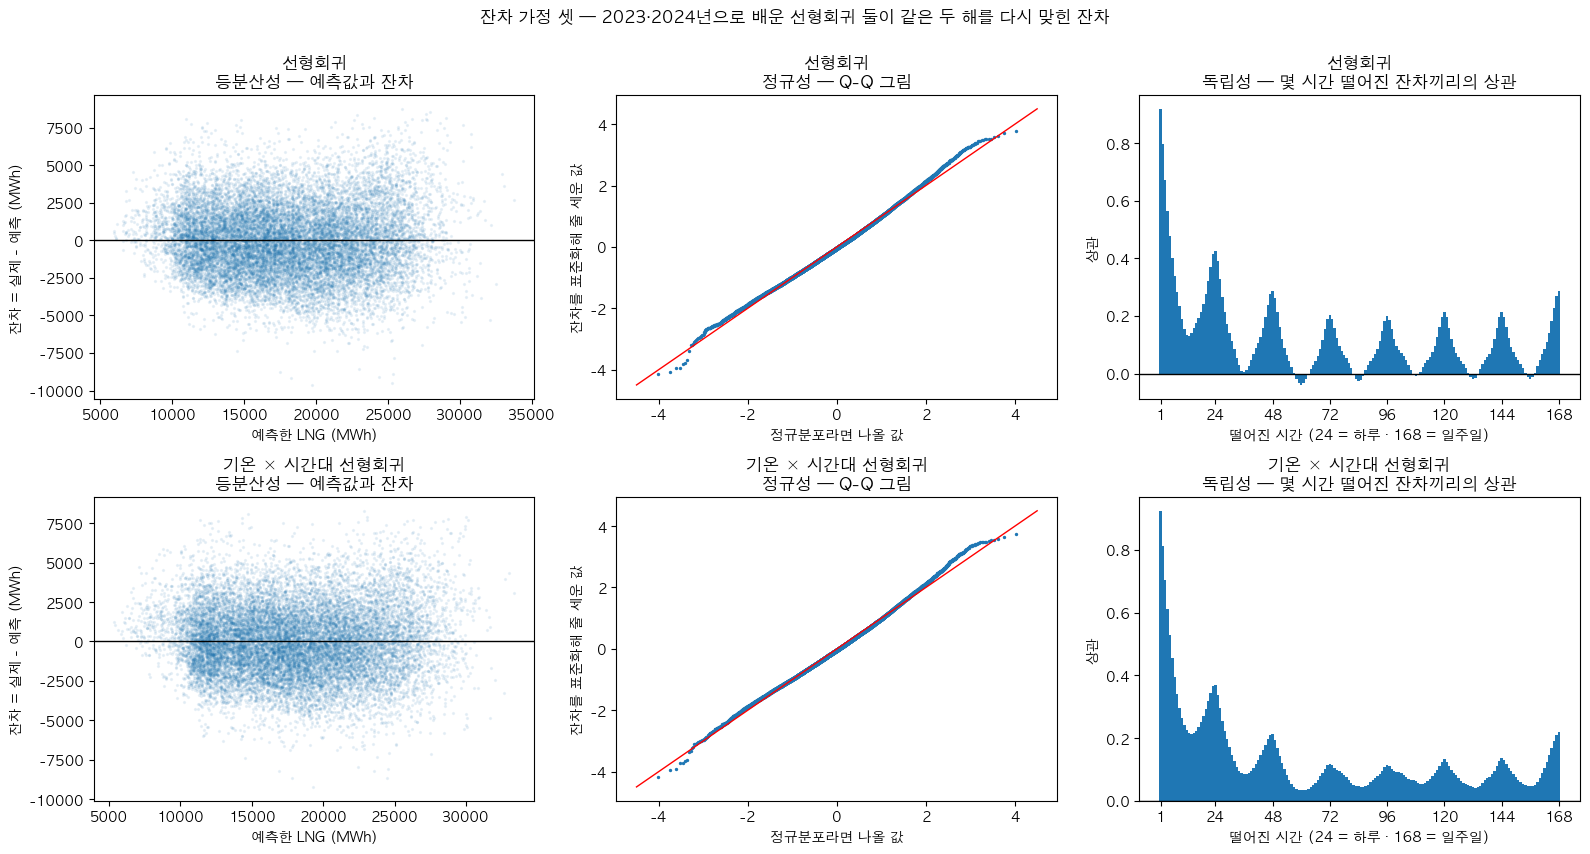

In [373]:
# 7단계 모델링과 검정 · 1-다
선형둘 = ["선형회귀", "기온 × 시간대 선형회귀"]                                          # 1-나와 같은 둘 — 1-나를 건너뛰고 이 셀만 돌려도 되게 다시 적는다
배운예측 = {이름: pd.Series(LinearRegression().fit(입력[이름][배움], y[배움]).predict(입력[이름][배움]), index=y[배움].index)
           for 이름 in 선형둘}                                                         # 두 해로 배우고, 배운 그 두 해를 다시 맞힌 값
잔차배움 = pd.DataFrame({이름: y[배움] - p for 이름, p in 배운예측.items()})             # 잔차 = 실제 LNG − 예측 LNG (MWh)

def 자기상관(e, k):                                                                    # k시간 떨어진 두 시각의 잔차 상관 — 자료가 빈 시각(2024년 8월 등)과는 짝을 짓지 않는다
    앞 = e.reindex(e.index - pd.Timedelta(hours=k)).values                             # 각 시각의 k시간 전 잔차
    있음 = ~np.isnan(앞)
    return np.corrcoef(e.values[있음], 앞[있음])[0, 1]

시차 = list(range(1, 169))                                                              # 1시간 ~ 168시간(일주일)
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for i, 이름 in enumerate(선형둘):
    e, p = 잔차배움[이름], 배운예측[이름]
    ax = axes[i, 0]                                                                     # 등분산성 — 예측값이 크든 작든 잔차가 퍼진 폭이 같은가
    ax.scatter(p, e, s=2, alpha=0.08, color="tab:blue")
    ax.axhline(0, color="black", lw=1)
    ax.set_title(f"{이름}\n등분산성 — 예측값과 잔차")
    ax.set_xlabel("예측한 LNG (MWh)"); ax.set_ylabel("잔차 = 실제 - 예측 (MWh)")    # 그림 글자의 빼기는 「-」로 — 맥 글꼴(AppleGothic)에 「−」가 없어 네모로 나온다(10-05)
    ax = axes[i, 1]                                                                     # 정규성 — 잔차를 줄 세운 값이 정규분포를 줄 세운 값과 한 선에 놓이나
    z = np.sort(((e - e.mean()) / e.std()).values)                                      # 잔차를 표준화해 작은 것부터 줄 세운다
    이론 = stats.norm.ppf((np.arange(1, len(z) + 1) - 0.5) / len(z))                    # 정규분포라면 같은 순서에 나올 값
    ax.scatter(이론, z, s=2, color="tab:blue")
    ax.plot([-4.5, 4.5], [-4.5, 4.5], color="red", lw=1)                                # 정규분포면 점이 이 선 위에 놓인다
    ax.set_title(f"{이름}\n정규성 — Q-Q 그림")
    ax.set_xlabel("정규분포라면 나올 값"); ax.set_ylabel("잔차를 표준화해 줄 세운 값")
    ax = axes[i, 2]                                                                     # 독립성 — 몇 시간 떨어진 잔차끼리 닮았나
    ax.bar(시차, [자기상관(e, k) for k in 시차], width=1.0, color="tab:blue")
    ax.axhline(0, color="black", lw=1)
    ax.set_xticks([1, 24, 48, 72, 96, 120, 144, 168])
    ax.set_title(f"{이름}\n독립성 — 몇 시간 떨어진 잔차끼리의 상관")
    ax.set_xlabel("떨어진 시간 (24 = 하루 · 168 = 일주일)"); ax.set_ylabel("상관")
plt.suptitle("잔차 가정 셋 — 2023·2024년으로 배운 선형회귀 둘이 같은 두 해를 다시 맞힌 잔차", y=1.0)
plt.tight_layout()
plt.show()

## 1-라 — 잔차 가정 셋을 숫자로 보기

**무엇을 보는 셀인가.** 1-다와 같은 잔차로, 가정마다 크기를 보여 주는 숫자([표 1] — 줄마다 「지켜질 때의 값」이 같이 있습니다)와 교재의 검정 p값([표 2])을 놓습니다.

In [374]:
# 7단계 모델링과 검정 · 1-라
def 더빈왓슨(e):                                                                       # Σ(바로 앞 시각과의 잔차 차이)² ÷ Σ잔차² — 바로 앞 시각이 있는 시각만 쓴다
    앞 = e.reindex(e.index - pd.Timedelta(hours=1)).values
    있음 = ~np.isnan(앞)
    return ((e.values[있음] - 앞[있음]) ** 2).sum() / (e.values ** 2).sum()

def 흩어짐비(e, p):                                                                     # 예측값 크기로 다섯 묶음을 만들고, 가장 큰 묶음과 가장 작은 묶음의 잔차 표준편차 비
    묶음 = pd.qcut(p, 5, labels=False)
    폭 = e.groupby(묶음).std()
    return 폭.iloc[-1] / 폭.iloc[0]

def 브로이시페이건(e, X):                                                               # 잔차 제곱을 입력 열로 맞힌 R² × 시각 수 — 열에 따라 잔차 흩어짐이 다르면 커진다
    LM = len(e) * LinearRegression().fit(X, e ** 2).score(X, e ** 2)
    return stats.chi2.sf(LM, X.shape[1])                                                 # p값

표1 = pd.DataFrame({이름: [f"{흩어짐비(잔차배움[이름], 배운예측[이름]):.2f}", f"{stats.skew(잔차배움[이름]):+.2f}",
                            f"{stats.kurtosis(잔차배움[이름], fisher=False):.2f}", f"{더빈왓슨(잔차배움[이름]):.2f}"]
                    for 이름 in 선형둘},
                   index=pd.Index(["등분산성 — 예측이 큰 1/5 묶음과 작은 1/5 묶음의 잔차 표준편차 비",
                                   "정규성 — 왜도(한쪽으로 치우친 정도)", "정규성 — 첨도(꼬리가 두꺼운 정도)",
                                   "독립성 — 더빈-왓슨 통계량"], name="가정 — 무엇으로 보나"))
표1.insert(0, "지켜질 때의 값", ["1 근처", "0 근처", "3 근처", "2 근처 (0에 가까울수록 이웃한 시각이 같은 쪽으로 틀린다)"])
표2 = pd.DataFrame({이름: [f"{브로이시페이건(잔차배움[이름], 입력[이름][배움]):.4f}", f"{stats.jarque_bera(잔차배움[이름]).pvalue:.4f}"]
                    for 이름 in 선형둘},
                   index=pd.Index(["등분산성 — 브로이시-페이건 검정", "정규성 — 자크-베라 검정"], name="가정 — 검정"))

print(f"1-다와 같은 잔차 — 2023·2024년 {len(잔차배움):,}시각, 선형회귀 둘")
print("[표 1] 크기로 본 잔차 가정 셋 — 줄마다 「지켜질 때의 값」과 비교한다")
display(표1)
print("[표 2] 검정의 p값 — 0.05보다 작으면 「가정이 깨졌다」로 읽는다. 시각이 많으면 작은 차이에도 p값이 작아져서 [표 1]을 같이 본다")
display(표2)

1-다와 같은 잔차 — 2023·2024년 16,767시각, 선형회귀 둘
[표 1] 크기로 본 잔차 가정 셋 — 줄마다 「지켜질 때의 값」과 비교한다


,지켜질 때의 값,선형회귀,기온 × 시간대 선형회귀
가정 — 무엇으로 보나,,,
등분산성 — 예측이 큰 1/5 묶음과 작은 1/5 묶음의 잔차 표준편차 비,1 근처,1.33,1.28
정규성 — 왜도(한쪽으로 치우친 정도),0 근처,+0.22,+0.21
정규성 — 첨도(꼬리가 두꺼운 정도),3 근처,3.17,3.21
독립성 — 더빈-왓슨 통계량,2 근처 (0에 가까울수록 이웃한 시각이 같은 쪽으로 틀린다),0.16,0.15


[표 2] 검정의 p값 — 0.05보다 작으면 「가정이 깨졌다」로 읽는다. 시각이 많으면 작은 차이에도 p값이 작아져서 [표 1]을 같이 본다


,선형회귀,기온 × 시간대 선형회귀
가정 — 검정,,
등분산성 — 브로이시-페이건 검정,0.0000,0.0000
정규성 — 자크-베라 검정,0.0000,0.0000


## 1-마 — 잔차의 이어짐을 같이 배우는 선형회귀로 바꾸면 2024년을 더 잘 맞히나

**무엇을 보는 셀인가.** 잔차가 바로 앞 시각의 잔차를 얼마나 닮는지(ρ)를 같이 배우는 선형회귀를 2023년으로 배워서, 2024년을 입력만으로 맞힙니다. 지금 선형회귀와 2024년 결정계수를 나란히 놓습니다([표 1]). 기준은 6단계 물음 6과 같습니다 — 0.002 넘게 높으면 7단계 비교에 더합니다.

In [375]:
# 7단계 모델링과 검정 · 1-마
선형둘 = ["선형회귀", "기온 × 시간대 선형회귀"]                                          # 1-나와 같은 둘 — 이 셀만 다시 돌려도 되게 다시 적는다
def 이어짐함께배우기(X, y, 되풀이=3):                                                    # 잔차가 바로 앞 시각과 이어지는 정도(ρ)를 같이 배우는 선형회귀 — 프레이스-윈스턴 방식
    Xc = np.column_stack([np.ones(len(X)), X.values])                                      # 절편 열을 붙인다
    β = np.linalg.lstsq(Xc, y.values, rcond=None)[0]                                       # 처음에는 보통 선형회귀로 기울기를 구한다
    앞X = pd.DataFrame(Xc, index=y.index).reindex(y.index - pd.Timedelta(hours=1)).values  # 각 시각의 1시간 전 입력
    앞y = y.reindex(y.index - pd.Timedelta(hours=1)).values                                 # 각 시각의 1시간 전 LNG
    있음 = ~np.isnan(앞y)                                                                   # 바로 앞 시각이 있는 시각만 쓴다(빈 날의 다음 시각은 뺀다)
    for _ in range(되풀이):
        e = y.values - Xc @ β                                                               # 지금 기울기로 낸 잔차
        e앞 = y.reindex(y.index - pd.Timedelta(hours=1)).values - np.nan_to_num(앞X) @ β     # 1시간 전 잔차
        ρ = np.dot(e[있음], e앞[있음]) / np.dot(e앞[있음], e앞[있음])                          # 잔차가 1시간 전 잔차를 얼마나 닮나
        β = np.linalg.lstsq(Xc[있음] - ρ * 앞X[있음], y.values[있음] - ρ * 앞y[있음], rcond=None)[0]   # 「지금 − ρ × 1시간 전」으로 바꿔 다시 배운다
    return β, ρ

연습배움 = 전체["year"] == 2023                                                          # 6단계와 같은 연습 — 2023년으로 배워
연습맞힘 = 전체["year"] == 2024                                                          # 2024년을 맞힌다
실제24 = y[연습맞힘]
def R2(실, 예): return 1 - ((실 - 예) ** 2).sum() / ((실 - 실.mean()) ** 2).sum()
줄 = []
for 이름 in 선형둘:
    X = 입력[이름]
    보통 = LinearRegression().fit(X[연습배움], y[연습배움]).predict(X[연습맞힘])                 # 지금 방식
    β, ρ = 이어짐함께배우기(X[연습배움], y[연습배움])
    이어짐 = np.column_stack([np.ones(int(연습맞힘.sum())), X[연습맞힘].values]) @ β            # 2024년은 앞 시각의 실제 LNG를 쓰지 않고 입력만으로 맞힌다
    a, b = R2(실제24, 보통), R2(실제24, 이어짐)
    줄.append({"모델": 이름, "배운 ρ": f"{ρ:.2f}", "지금 방식": f"{a:.4f}", "이어짐을 함께 배운 방식": f"{b:.4f}",
               "차이": f"{b - a:+.4f}", "0.002 넘게 높나": "넘는다" if b - a > 0.002 else "못 넘는다"})
print("2023년으로 배워 2024년을 맞혔다 — 6단계 물음 6과 같은 연습, 같은 기준(0.002)")
print("[표 1] 잔차의 이어짐(ρ)을 함께 배운 선형회귀와 지금 선형회귀의 2024년 결정계수")
display(pd.DataFrame(줄).set_index("모델"))

2023년으로 배워 2024년을 맞혔다 — 6단계 물음 6과 같은 연습, 같은 기준(0.002)
[표 1] 잔차의 이어짐(ρ)을 함께 배운 선형회귀와 지금 선형회귀의 2024년 결정계수


,배운 ρ,지금 방식,이어짐을 함께 배운 방식,차이,0.002 넘게 높나
모델,,,,,
선형회귀,0.94,0.7524,0.7328,-0.0196,못 넘는다
기온 × 시간대 선형회귀,0.95,0.7679,0.7443,-0.0237,못 넘는다


## 1-바 — 잔차의 이어짐을 감안하면 기울기의 표준오차와 p값이 얼마나 달라지나

**무엇을 보는 셀인가.** 2023·2024년으로 배운 선형회귀의 기울기 여섯에 대해 표준오차를 세 가지로 냅니다 — 보통 · 등분산이 아닌 것만 감안 · 이어짐까지 감안(1주일 떨어진 짝까지)([표 1]). 그 표준오차로 낸 p값을 나란히 놓습니다([표 2]). 기울기와 예측은 바뀌지 않습니다.

In [376]:
# 7단계 모델링과 검정 · 1-바
def 표준오차들(X, y, 시차=168):                                                          # 같은 기울기의 표준오차를 세 가지로 낸다
    Xc = np.column_stack([np.ones(len(X)), X.values])
    β = np.linalg.lstsq(Xc, y.values, rcond=None)[0]                                       # 기울기 — 세 가지 모두 같다
    e = y.values - Xc @ β                                                                  # 잔차
    A = np.linalg.inv(Xc.T @ Xc)
    보통 = np.sqrt(np.diag(A) * (e @ e) / (len(e) - Xc.shape[1]))                           # 보통 표준오차 — 잔차가 독립이고 등분산이라고 칠 때
    u = pd.DataFrame(Xc * e[:, None], index=y.index)                                       # 시각마다 (입력 × 잔차)
    S0 = u.values.T @ u.values
    등분산만 = np.sqrt(np.diag(A @ S0 @ A))                                                 # 등분산이 아닌 것만 감안(시차 0)
    S = S0.copy()
    for l in range(1, 시차 + 1):                                                            # 1~168시간 떨어진 짝의 곱을 더한다(뉴이-웨스트, 바틀렛 가중치)
        앞 = u.reindex(u.index - pd.Timedelta(hours=l)).values
        있음 = ~np.isnan(앞[:, 0])
        G = u.values[있음].T @ 앞[있음]
        S += (1 - l / (시차 + 1)) * (G + G.T)
    이어짐까지 = np.sqrt(np.diag(A @ S @ A))                                                 # 이어짐까지 감안
    열 = ["절편"] + list(X.columns)
    return pd.DataFrame({"기울기": β, "보통": 보통, "등분산만 감안": 등분산만, "이어짐까지 감안": 이어짐까지}, index=열)

볼열 = ["16도보다 추운 만큼", "24도보다 더운 만큼", "3시간 동안 바뀐 만큼 (추운 쪽)", "3시간 동안 바뀐 만큼 (더운 쪽)", "일사", "날_일"]
표 = 표준오차들(입력["선형회귀"][배움], y[배움]).loc[볼열]                                    # 두 해로 배운 선형회귀 — 1-다·1-라와 같은 모델
표1 = pd.DataFrame({"기울기 (MWh)": 표["기울기"].map("{:+,.0f}".format),
                    "보통 표준오차": 표["보통"].map("{:,.0f}".format),
                    "등분산만 감안": 표["등분산만 감안"].map("{:,.0f}".format),
                    "이어짐까지 감안": 표["이어짐까지 감안"].map("{:,.0f}".format),
                    "이어짐까지 ÷ 보통 (배)": (표["이어짐까지 감안"] / 표["보통"]).map("{:.1f}".format)}).rename_axis("열")
p = lambda 기울기, 오차: pd.Series(2 * stats.norm.sf(np.abs(기울기 / 오차)), index=기울기.index)   # 기울기가 0이라는 귀무가설의 p값
표2 = pd.DataFrame({"p값 — 보통": p(표["기울기"], 표["보통"]).map("{:.4f}".format),
                    "p값 — 이어짐까지 감안": p(표["기울기"], 표["이어짐까지 감안"]).map("{:.4f}".format)}).rename_axis("열")
print(f"2023·2024년 {int(배움.sum()):,}시각으로 배운 선형회귀의 기울기 가운데 여섯 — 기울기는 그대로이고 표준오차만 세 가지로 냈다")
print("[표 1] 표준오차 — 이어짐까지 감안할 때 1주일(168시간) 떨어진 짝까지 넣었다")
display(표1)
print("[표 2] 기울기가 0이라는 귀무가설의 p값 — 0.05보다 작으면 「이 열은 LNG와 관계가 있다」로 읽는다")
display(표2)

2023·2024년 16,767시각으로 배운 선형회귀의 기울기 가운데 여섯 — 기울기는 그대로이고 표준오차만 세 가지로 냈다
[표 1] 표준오차 — 이어짐까지 감안할 때 1주일(168시간) 떨어진 짝까지 넣었다


,기울기 (MWh),보통 표준오차,등분산만 감안,이어짐까지 감안,이어짐까지 ÷ 보통 (배)
열,,,,,
16도보다 추운 만큼,+281,5,6,23,4.3
24도보다 더운 만큼,+977,15,16,64,4.4
3시간 동안 바뀐 만큼 (추운 쪽),+160,15,15,36,2.4
3시간 동안 바뀐 만큼 (더운 쪽),-8,24,24,51,2.1
일사,"-2,604",40,44,120,3.0
날_일,"-4,482",69,66,163,2.4


[표 2] 기울기가 0이라는 귀무가설의 p값 — 0.05보다 작으면 「이 열은 LNG와 관계가 있다」로 읽는다


,p값 — 보통,p값 — 이어짐까지 감안
열,,
16도보다 추운 만큼,0.0000,0.0000
24도보다 더운 만큼,0.0000,0.0000
3시간 동안 바뀐 만큼 (추운 쪽),0.0000,0.0000
3시간 동안 바뀐 만큼 (더운 쪽),0.7461,0.8793
일사,0.0000,0.0000
날_일,0.0000,0.0000


## 1-사 — 이어짐을 감안하는 범위를 일주일보다 넓히면 표준오차와 p값이 달라지나

**무엇을 보는 셀인가.** 1-바와 같은 선형회귀(2023·2024년)의 여섯 열에 대해, 감안하는 범위를 일주일 · 2주 · 4주로 넓혀 표준오차([표 1])와 p값([표 2])을 다시 냅니다. 기울기는 그대로이고, 「일주일」 칸은 1-바의 「이어짐까지 감안」과 같은 숫자입니다. 2025년은 쓰지 않습니다.

In [377]:
# 7단계 모델링과 검정 · 1-사
Xs = 입력["선형회귀"][배움]                                                              # 1-바와 같은 선형회귀 — 두 해(2023·2024년)의 67열
Xc = np.column_stack([np.ones(len(Xs)), Xs.values])                                      # 절편 열을 붙인다
β = np.linalg.lstsq(Xc, y[배움].values, rcond=None)[0]                                   # 기울기 — 범위를 바꿔도 그대로다
e = y[배움].values - Xc @ β                                                              # 잔차
A = np.linalg.inv(Xc.T @ Xc)
u = pd.DataFrame(Xc * e[:, None], index=Xs.index)                                        # 시각마다 (입력 × 잔차)
범위들 = {"일주일 (168시간)": 168, "2주 (336시간)": 336, "4주 (672시간)": 672}            # 이어짐을 감안하는 범위 — 몇 시간 떨어진 짝까지 넣나
G = {}                                                                                   # l시간 떨어진 짝의 곱 — 한 번만 구해 범위마다 다시 쓴다
for l in range(1, max(범위들.values()) + 1):
    앞 = u.reindex(u.index - pd.Timedelta(hours=l)).values                               # l시간 전 시각의 값(그 시각이 없으면 빈 칸)
    있음 = ~np.isnan(앞[:, 0])
    g = u.values[있음].T @ 앞[있음]
    G[l] = g + g.T
S0 = u.values.T @ u.values
오차 = {"보통": np.sqrt(np.diag(A) * (e @ e) / (len(e) - Xc.shape[1]))}                   # 보통 표준오차 — 1-바와 같다
for 이름, L in 범위들.items():                                                            # 뉴이-웨스트(바틀렛 가중치) — 1-바와 같은 식, 범위만 바꾼다
    S = S0 + sum((1 - l / (L + 1)) * G[l] for l in range(1, L + 1))
    오차[이름] = np.sqrt(np.diag(A @ S @ A))

열 = ["절편"] + list(Xs.columns)
볼열 = ["16도보다 추운 만큼", "24도보다 더운 만큼", "3시간 동안 바뀐 만큼 (추운 쪽)", "3시간 동안 바뀐 만큼 (더운 쪽)", "일사", "날_일"]   # 1-바와 같은 여섯 열
기울기 = pd.Series(β, index=열).loc[볼열]
표준 = pd.DataFrame(오차, index=열).loc[볼열]
표1 = pd.concat([기울기.map("{:+,.0f}".format).rename("기울기 (MWh)"), 표준.apply(lambda s: s.map("{:,.0f}".format))], axis=1).rename_axis("열")
p값 = 표준.apply(lambda s: pd.Series(2 * stats.norm.sf(np.abs(기울기 / s)), index=볼열))     # 기울기가 0이라는 귀무가설의 p값
표2 = p값.apply(lambda s: s.map("{:.4f}".format)).rename_axis("열")
print(f"1-바와 같은 선형회귀(2023·2024년 {len(Xs):,}시각) — 이어짐을 감안하는 범위를 일주일 · 2주 · 4주로 넓혀 표준오차를 다시 냈다. 기울기는 그대로다")
print("[표 1] 기울기와 표준오차 — 「보통」은 잔차가 서로 독립이라고 칠 때, 나머지는 그 범위 안에서 떨어진 짝까지 감안할 때")
display(표1)
print("[표 2] 기울기가 0이라는 귀무가설의 p값 — 0.05보다 작으면 「이 열은 LNG와 관계가 있다」로 읽는다")
display(표2)

1-바와 같은 선형회귀(2023·2024년 16,767시각) — 이어짐을 감안하는 범위를 일주일 · 2주 · 4주로 넓혀 표준오차를 다시 냈다. 기울기는 그대로다
[표 1] 기울기와 표준오차 — 「보통」은 잔차가 서로 독립이라고 칠 때, 나머지는 그 범위 안에서 떨어진 짝까지 감안할 때


,기울기 (MWh),보통,일주일 (168시간),2주 (336시간),4주 (672시간)
열,,,,,
16도보다 추운 만큼,+281,5,23,22,20
24도보다 더운 만큼,+977,15,64,70,80
3시간 동안 바뀐 만큼 (추운 쪽),+160,15,36,42,51
3시간 동안 바뀐 만큼 (더운 쪽),-8,24,51,53,55
일사,"-2,604",40,120,127,133
날_일,"-4,482",69,163,177,208


[표 2] 기울기가 0이라는 귀무가설의 p값 — 0.05보다 작으면 「이 열은 LNG와 관계가 있다」로 읽는다


,보통,일주일 (168시간),2주 (336시간),4주 (672시간)
열,,,,
16도보다 추운 만큼,0.0000,0.0000,0.0000,0.0000
24도보다 더운 만큼,0.0000,0.0000,0.0000,0.0000
3시간 동안 바뀐 만큼 (추운 쪽),0.0000,0.0000,0.0002,0.0018
3시간 동안 바뀐 만큼 (더운 쪽),0.7461,0.8793,0.8851,0.8895
일사,0.0000,0.0000,0.0000,0.0000
날_일,0.0000,0.0000,0.0000,0.0000


# 물음 2 — 2025년 채점: 모델 넷이 기준선보다 잘 맞히나, 모델을 쓸지 말지

> **결정** — 모델 넷 모두 2025년에도 기준선 「달·시각·날별 평균」보다 잘 맞혔다. 넷 다 쓰고, 하나를 고르는 것은 8단계에서 한다

## 2-가 — 2025년을 맞히면 모델 넷이 「달·시각·날별 평균」보다 결정계수가 높나

**무엇을 보는 셀인가.** 기준선 넷과 모델 넷이 2025년을 맞힌 결정계수와 「달·시각·날별 평균」보다 높은지([표 1]), 같은 예측의 평균 절대 오차([표 2] — 9단계에 쓸 「평소에 틀리는 정도」)입니다. 모델을 배우느라 30초쯤 걸립니다.

In [378]:
# 7단계 모델링과 검정 · 2-가
원본 = pd.read_csv(os.path.join(HOT, "features_2023_2024_2025.csv"), encoding="utf-8-sig", usecols=["ts", "lng_mwh"])   # 2025년 LNG를 처음 꺼낸다 — 이 노트북에서 여기 한 곳
원본["ts"] = pd.to_datetime(원본["ts"])
채점 = 전체["year"] == 2025                                                                     # 채점하는 해
시25 = 전체.index[채점]                                                                          # 2025년 시각
실제25 = 원본.set_index("ts")["lng_mwh"].reindex(시25)                                            # 2025년 시각마다 실제 LNG(MWh)

모델들 = {"선형회귀": (lambda: LinearRegression(), "선형회귀"),                                     # 1-가와 같은 넷 — 이 셀만 다시 돌려도 되게 다시 적는다
          "기온 × 시간대 선형회귀": (lambda: LinearRegression(), "기온 × 시간대 선형회귀"),
          "랜덤포레스트": (lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=1, max_features=0.5,
                                                      n_jobs=-1, random_state=0), "트리 계열"),
          "그래디언트 부스팅": (lambda: HistGradientBoostingRegressor(early_stopping=False, random_state=0), "트리 계열")}

예측25 = {}                                                                                     # 방법 이름: 2025년 시각마다 예측
y두해 = tbl.loc[tbl["year"].isin([2023, 2024]), "lng_mwh"]                                      # 기준선이 쓰는 두 해 LNG
쉬는날 = tbl["날 종류"].isin(["토", "일", "공휴일", "명절"])                                       # 6단계와 같은 쉬는 날
예측25["① 한 해 평균"] = pd.Series(y두해.mean(), index=시25)                                      # 두 해 모든 시각의 평균 하나
시각평균 = y두해.groupby(tbl.loc[y두해.index, "hour24"]).mean()                                   # 시각(0~23시)마다 평균
예측25["② 시각별 평균"] = pd.Series(시각평균.loc[tbl.loc[시25, "hour24"]].values, index=시25)
셋평균 = y두해.groupby([tbl.loc[y두해.index, "month"], tbl.loc[y두해.index, "hour24"], 쉬는날.loc[y두해.index]]).mean()   # 같은 달·같은 시각·같은 날 종류의 평균
키 = pd.MultiIndex.from_arrays([tbl.loc[시25, "month"], tbl.loc[시25, "hour24"], 쉬는날.loc[시25]])
예측25["③ 달·시각·날별 평균"] = pd.Series(셋평균.reindex(키).values, index=시25)
전52 = y두해.reindex(시25 - pd.Timedelta(days=364)).values                                       # 364일 전 같은 요일 같은 시각
전104 = y두해.reindex(시25 - pd.Timedelta(days=728)).values                                      # 그날이 두 해에 없으면 728일 전
예측25["④ 52주 전 같은 요일"] = pd.Series(np.where(np.isnan(전52), 전104, 전52), index=시25)
for 이름, (만들기, 열) in 모델들.items():                                                        # 모델 넷 — 2023·2024년으로 배우고 2025년을 입력만으로 맞힌다
    X = 입력[열]
    예측25[이름] = pd.Series(만들기().fit(X[배움], y[배움]).predict(X[채점]), index=시25)

def R2(실, 예): return 1 - ((실 - 예) ** 2).sum() / ((실 - 실.mean()) ** 2).sum()                  # 결정계수 — 6단계와 같은 식
값 = pd.Series({이름: R2(실제25, p) for 이름, p in 예측25.items()})
기준 = 값["③ 달·시각·날별 평균"]                                                                 # 2024년에 가장 나았던 기준선
표1 = pd.DataFrame({"2025년 결정계수": 값.map("{:.4f}".format),
                    "「달·시각·날별 평균」과의 차이": (값.round(4) - round(기준, 4)).map("{:+.4f}".format),
                    "그보다 높나": ["—"] * 4 + ["높다" if v > 기준 else "높지 않다" for v in 값.iloc[4:]]}).rename_axis("방법")
표2 = pd.Series({이름: (실제25 - p).abs().mean() for 이름, p in 예측25.items()}).map("{:,.0f}".format).rename("평균 절대 오차 (MWh)").to_frame().rename_axis("방법")

print(f"2023·2024년으로 배워 2025년 {len(시25):,}시각을 맞혔다 — 「52주 전 같은 요일」에서 728일 전 값을 쓴 시각 {int(np.isnan(전52).sum()):,}개")
print("[표 1] 2025년 결정계수 — 2024년에 가장 나았던 기준선 「달·시각·날별 평균」보다 높으면 낫다(6단계 물음 2)")
display(표1)
print("[표 2] 같은 예측의 평균 절대 오차 — 한 시각에 평균 몇 MWh 틀렸나(9단계의 「평소에 틀리는 정도」)")
display(표2)

2023·2024년으로 배워 2025년 8,760시각을 맞혔다 — 「52주 전 같은 요일」에서 728일 전 값을 쓴 시각 792개
[표 1] 2025년 결정계수 — 2024년에 가장 나았던 기준선 「달·시각·날별 평균」보다 높으면 낫다(6단계 물음 2)


,2025년 결정계수,「달·시각·날별 평균」과의 차이,그보다 높나
방법,,,
① 한 해 평균,-0.0023,-0.6701,—
② 시각별 평균,0.2909,-0.3769,—
③ 달·시각·날별 평균,0.6678,+0.0000,—
④ 52주 전 같은 요일,0.4350,-0.2328,—
선형회귀,0.7007,+0.0329,높다
기온 × 시간대 선형회귀,0.7280,+0.0602,높다
랜덤포레스트,0.7427,+0.0749,높다
그래디언트 부스팅,0.7553,+0.0875,높다


[표 2] 같은 예측의 평균 절대 오차 — 한 시각에 평균 몇 MWh 틀렸나(9단계의 「평소에 틀리는 정도」)


,평균 절대 오차 (MWh)
방법,
① 한 해 평균,"4,876"
② 시각별 평균,"4,019"
③ 달·시각·날별 평균,"2,723"
④ 52주 전 같은 요일,"3,419"
선형회귀,"2,652"
기온 × 시간대 선형회귀,"2,503"
랜덤포레스트,"2,421"
그래디언트 부스팅,"2,364"


## 2-나 — 2023·2024년에 본 기온·일사 범위 밖인 2025년 시각을 빼면 결과가 달라지나

**무엇을 보는 셀인가.** 2-가의 예측을 그대로 쓰고, 모든 시각과 범위 밖 시각을 뺀 것을 나란히 놓습니다 — 결정계수([표 1])와 평균 절대 오차([표 2]).

In [379]:
# 7단계 모델링과 검정 · 2-나
본 = 전체.loc[배움, ["ta", "icsr"]]                                                              # 배울 때 본 기온·일사 — 6단계 3-나와 같은 범위
기상25 = 전체.loc[채점, ["ta", "icsr"]]                                                          # 2025년 기온·일사
밖 = ((기상25["ta"] < 본["ta"].min()) | (기상25["ta"] > 본["ta"].max()) | (기상25["icsr"] > 본["icsr"].max())).values   # 범위 밖 시각
안 = ~밖
이름들 = list(예측25)
표1 = pd.DataFrame({"모든 시각": [f"{R2(실제25, 예측25[n]):.4f}" for n in 이름들],
                    "범위 밖 시각을 뺌": [f"{R2(실제25[안], 예측25[n][안]):.4f}" for n in 이름들]}, index=pd.Index(이름들, name="방법"))
표2 = pd.DataFrame({"모든 시각": [f"{(실제25 - 예측25[n]).abs().mean():,.0f}" for n in 이름들],
                    "범위 밖 시각을 뺌": [f"{(실제25[안] - 예측25[n][안]).abs().mean():,.0f}" for n in 이름들]}, index=pd.Index(이름들, name="방법"))

print(f"2025년 {len(밖):,}시각 가운데 2023·2024년에 본 기온·일사 범위 밖인 {int(밖.sum())}시각을 뺐다(6단계 3-나와 같은 기준)")
print("[표 1] 2025년 결정계수 — 모든 시각과, 범위 밖 시각을 뺀 것")
display(표1)
print("[표 2] 평균 절대 오차(MWh) — 모든 시각과, 범위 밖 시각을 뺀 것")
display(표2)

2025년 8,760시각 가운데 2023·2024년에 본 기온·일사 범위 밖인 30시각을 뺐다(6단계 3-나와 같은 기준)
[표 1] 2025년 결정계수 — 모든 시각과, 범위 밖 시각을 뺀 것


,모든 시각,범위 밖 시각을 뺌
방법,,
① 한 해 평균,-0.0023,-0.0019
② 시각별 평균,0.2909,0.2900
③ 달·시각·날별 평균,0.6678,0.6662
④ 52주 전 같은 요일,0.4350,0.4316
선형회귀,0.7007,0.6989
기온 × 시간대 선형회귀,0.7280,0.7264
랜덤포레스트,0.7427,0.7410
그래디언트 부스팅,0.7553,0.7538


[표 2] 평균 절대 오차(MWh) — 모든 시각과, 범위 밖 시각을 뺀 것


,모든 시각,범위 밖 시각을 뺌
방법,,
① 한 해 평균,"4,876","4,864"
② 시각별 평균,"4,019","4,010"
③ 달·시각·날별 평균,"2,723","2,721"
④ 52주 전 같은 요일,"3,419","3,419"
선형회귀,"2,652","2,653"
기온 × 시간대 선형회귀,"2,503","2,502"
랜덤포레스트,"2,421","2,422"
그래디언트 부스팅,"2,364","2,364"


## 2-다 — 랜덤포레스트: 6단계에서 2024년으로 고른 설정이 2025년에도 바꾸기 전 설정보다 나은가

**무엇을 보는 셀인가.** 바꾸기 전 설정(잎 하나에 최소 5시각 · 가지를 나눌 때마다 모든 열)으로 같은 두 해를 배워 2025년을 맞히고, 고른 설정(2-가)과 결정계수를 나란히 놓습니다([표 1]). 결과가 어떻든 설정은 바꾸지 않습니다.

In [380]:
# 7단계 모델링과 검정 · 2-다
전설정 = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=1.0, n_jobs=-1, random_state=0)   # 6단계 물음 6 전의 설정(5-다)
예전 = pd.Series(전설정.fit(입력["트리 계열"][배움], y[배움]).predict(입력["트리 계열"][채점]), index=시25)   # 같은 두 해로 배우고 2025년을 맞힌다
표1 = pd.DataFrame({"2024년 결정계수 (6단계 6-바)": ["0.7701", "0.7618"],
                    "2025년 결정계수": [f"{R2(실제25, 예측25['랜덤포레스트']):.4f}", f"{R2(실제25, 예전):.4f}"]},
                   index=pd.Index(["고른 설정 (잎 1 · 가지마다 열의 절반)", "바꾸기 전 설정 (잎 5 · 가지마다 모든 열)"], name="랜덤포레스트 설정"))
print("두 설정 모두 2023·2024년으로 배워 2025년을 맞혔다 — 참고로 보는 셀이고, 설정은 바꾸지 않는다")
print("[표 1] 랜덤포레스트 두 설정의 결정계수")
display(표1)

두 설정 모두 2023·2024년으로 배워 2025년을 맞혔다 — 참고로 보는 셀이고, 설정은 바꾸지 않는다
[표 1] 랜덤포레스트 두 설정의 결정계수


,2024년 결정계수 (6단계 6-바),2025년 결정계수
랜덤포레스트 설정,,
고른 설정 (잎 1 · 가지마다 열의 절반),0.7701,0.7427
바꾸기 전 설정 (잎 5 · 가지마다 모든 열),0.7618,0.7421


# 물음 3 — 2025년에 어디서 어떻게 틀렸나

> **결정** — 2025년에 모델은 낮에 예측이 실제보다 컸고(늘어난 태양광), 달마다 틀린 쪽은 원전과 석탄 발전량이 평소와 달랐던 쪽과 맞았으며(12달 가운데 10달), 30도 넘는 시각 · 토요일 · 며칠 이어진 날에 크게 틀렸다(그날 틀린 양도 대부분 원전 · 석탄 발전량이 평소와 달랐던 만큼이고, 그다음이 수요). 모델은 그대로 두고(가), 찾은 것은 11단계 한계 · 9단계 · 물음 4로 넘긴다

## 3-나 — 2025년에 예측이 실제보다 작았나, 컸나 (달마다 · 시간 묶음마다)

**무엇을 보는 셀인가.** 시각마다 잔차(실제 LNG − 모델이 맞힌 LNG)를 내서 달마다([표 1]), 하루의 시간 묶음마다([표 2]) 평균합니다. +면 그 달(또는 그 시간 묶음)에 평균으로 보면 예측이 실제보다 작았다는 뜻이고, −면 컸다는 뜻입니다. 0에 가까우면 예측이 작았던 만큼과 컸던 만큼이 비슷했다는 뜻이고, 얼마나 틀렸는지는 3-다에서 봅니다. 모델 넷 옆에 기준선(2023·2024년의 같은 달 · 같은 시각 · 같은 날 종류의 평균)도 놓았습니다 — 기준선의 잔차는 2025년 LNG가 지난 두 해의 같은 때보다 얼마나 높았나(또는 낮았나)를, 날씨를 감안하지 않고 보여 줍니다. 시간 묶음 다섯은 6단계 3-다와 같습니다. 물음 2에서 남긴 물음(둘 다 떨어진 것이 데이터가 달라서인가, 2025년이 달라서인가) 가운데 이 셀로 볼 수 있는 것은 「2025년 한 해 내내 예측이 실제보다 작았나(또는 컸나)」까지입니다.

In [381]:
# 7단계 모델링과 검정 · 3-나
assert "예측25" in globals(), "2-가를 먼저 돌려 주세요 — 2025년에 맞힌 값과 실제 값이 2-가에서 만들어집니다"
이름 = {"③ 달·시각·날별 평균": "기준선(달·시각·날별 평균)", "선형회귀": "선형회귀",
        "기온 × 시간대 선형회귀": "기온 × 시간대 선형회귀", "랜덤포레스트": "랜덤포레스트",
        "그래디언트 부스팅": "그래디언트 부스팅"}                                          # 2024년에 가장 나았던 기준선 + 모델 넷
잔차 = pd.DataFrame({짧게: 실제25 - 예측25[긴] for 긴, 짧게 in 이름.items()})             # 시각마다 잔차 = 실제 − 맞힌 값
묶음 = pd.cut(잔차.index.hour, bins=[-1, 5, 9, 15, 19, 23],
             labels=["0~5시 (밤)", "6~9시", "10~15시 (낮)", "16~19시", "20~23시"])      # 6단계 3-다와 같은 시간 묶음 다섯
표1 = 잔차.groupby(잔차.index.month).mean()                                               # 달마다 평균
표1.index = [f"{m}월" for m in 표1.index]
표1.loc["한 해"] = 잔차.mean()                                                            # 맨 아래 — 2025년 전체
표2 = 잔차.groupby(묶음, observed=True).mean()                                           # 시간 묶음마다 평균
부호 = lambda 표: 표.apply(lambda 칸: 칸.map("{:+,.0f}".format))                           # 부호와 천 단위 쉼표
print(f"2025년 {len(잔차):,}시각 — 잔차 = 실제 LNG − 맞힌 LNG · 단위 MWh · +면 예측이 실제보다 작았고, −면 컸다")
print("[표 1] 달마다 평균 잔차 — 맨 아래 줄은 2025년 한 해")
display(부호(표1).rename_axis("달"))
print("[표 2] 하루의 시간 묶음마다 평균 잔차")
display(부호(표2).rename_axis("시간 묶음"))

2025년 8,760시각 — 잔차 = 실제 LNG − 맞힌 LNG · 단위 MWh · +면 예측이 실제보다 작았고, −면 컸다
[표 1] 달마다 평균 잔차 — 맨 아래 줄은 2025년 한 해


,기준선(달·시각·날별 평균),선형회귀,기온 × 시간대 선형회귀,랜덤포레스트,그래디언트 부스팅
달,,,,,
1월,+553,+484,+479,+566,+591
2월,"+3,050","+2,138","+2,196","+2,189","+1,955"
3월,+846,+794,+806,"+1,034",+954
4월,"+2,022","+1,877","+1,901","+2,055","+2,040"
5월,+197,-239,-206,+18,-176
6월,-953,"-1,178","-1,106","-1,157","-1,066"
7월,-901,"-2,652","-2,065","-1,698","-1,686"
8월,+957,+296,+564,+383,+343
9월,"-2,879","-2,443","-2,506","-2,049","-2,177"


[표 2] 하루의 시간 묶음마다 평균 잔차


,기준선(달·시각·날별 평균),선형회귀,기온 × 시간대 선형회귀,랜덤포레스트,그래디언트 부스팅
시간 묶음,,,,,
0~5시 (밤),+437,+32,+317,+180,+182
6~9시,+87,-230,-153,-230,-215
10~15시 (낮),-646,-789,-846,-696,-748
16~19시,+820,+555,+570,+732,+661
20~23시,+889,+545,+619,+535,+567


## 3-다 — 2025년에 얼마나 틀렸나 (달마다 · 시간 묶음마다)

**무엇을 보는 셀인가.** 시각마다 틀린 크기(잔차에서 +와 −를 뗀 것)를 달마다([표 1]), 시간 묶음마다([표 2]) 평균합니다 — 한 시각에 평균 몇 MWh 틀렸나입니다. 맨 오른쪽 칸에는 그 달(또는 그 시간 묶음)에 기준선보다 더 틀린 모델을 적었습니다. [표 1]의 「한 해」 줄은 2-가 [표 2]와 같은 숫자입니다.

In [382]:
# 7단계 모델링과 검정 · 3-다
assert "예측25" in globals(), "2-가를 먼저 돌려 주세요 — 2025년에 맞힌 값과 실제 값이 2-가에서 만들어집니다"
이름 = {"③ 달·시각·날별 평균": "기준선(달·시각·날별 평균)", "선형회귀": "선형회귀",
        "기온 × 시간대 선형회귀": "기온 × 시간대 선형회귀", "랜덤포레스트": "랜덤포레스트",
        "그래디언트 부스팅": "그래디언트 부스팅"}                                          # 3-나와 같은 다섯
기준 = "기준선(달·시각·날별 평균)"
모델 = [짧게 for 짧게 in 이름.values() if 짧게 != 기준]                                    # 모델 넷
오차 = pd.DataFrame({짧게: (실제25 - 예측25[긴]).abs() for 긴, 짧게 in 이름.items()})     # 시각마다 틀린 크기(+와 −를 뗀다)
묶음 = pd.cut(오차.index.hour, bins=[-1, 5, 9, 15, 19, 23],
             labels=["0~5시 (밤)", "6~9시", "10~15시 (낮)", "16~19시", "20~23시"])      # 3-나와 같은 시간 묶음
표1 = 오차.groupby(오차.index.month).mean()                                               # 달마다 평균 절대 오차
표1.index = [f"{m}월" for m in 표1.index]
표1.loc["한 해"] = 오차.mean()                                                            # 맨 아래 — 2-가 [표 2]와 같은 숫자
표2 = 오차.groupby(묶음, observed=True).mean()                                           # 시간 묶음마다 평균 절대 오차
def 글(표):                                                                               # 천 단위 쉼표 + 그 줄에서 기준선보다 더 틀린 모델
    t = 표.apply(lambda 칸: 칸.map("{:,.0f}".format))
    t["기준선보다 더 틀린 모델"] = [" · ".join(m for m in 모델 if 표.loc[i, m] > 표.loc[i, 기준]) or "없음"
                                  for i in 표.index]
    return t
print("2025년 — 평균 절대 오차 = 한 시각에 평균 몇 MWh 틀렸나(+와 −를 떼고 크기만)")
print("[표 1] 달마다 평균 절대 오차 — 2024년에는 선형회귀가 4 · 5 · 7 · 11월에 기준선보다 더 틀렸다(6단계 2-다)")
display(글(표1).rename_axis("달"))
print("[표 2] 하루의 시간 묶음마다 평균 절대 오차")
display(글(표2).rename_axis("시간 묶음"))

2025년 — 평균 절대 오차 = 한 시각에 평균 몇 MWh 틀렸나(+와 −를 떼고 크기만)
[표 1] 달마다 평균 절대 오차 — 2024년에는 선형회귀가 4 · 5 · 7 · 11월에 기준선보다 더 틀렸다(6단계 2-다)


,기준선(달·시각·날별 평균),선형회귀,기온 × 시간대 선형회귀,랜덤포레스트,그래디언트 부스팅,기준선보다 더 틀린 모델
달,,,,,,
1월,"2,029","2,067","1,973","1,969","1,879",선형회귀
2월,"3,712","3,116","3,101","3,077","2,885",없음
3월,"2,889","2,926","2,846","2,628","2,520",선형회귀
4월,"3,202","2,992","2,887","2,747","2,679",없음
5월,"2,182","1,986","1,857","1,782","1,769",없음
6월,"2,390","2,455","2,319","2,250","2,169",선형회귀
7월,"3,035","3,504","2,901","2,860","2,817",선형회귀
8월,"2,677","2,888","2,496","2,386","2,361",선형회귀
9월,"3,629","3,218","3,263","2,836","2,830",없음


[표 2] 하루의 시간 묶음마다 평균 절대 오차


,기준선(달·시각·날별 평균),선형회귀,기온 × 시간대 선형회귀,랜덤포레스트,그래디언트 부스팅,기준선보다 더 틀린 모델
시간 묶음,,,,,,
0~5시 (밤),"2,492","2,887","2,594","2,396","2,326",선형회귀 · 기온 × 시간대 선형회귀
6~9시,"2,601","2,759","2,486","2,432","2,386",선형회귀
10~15시 (낮),"2,915","2,402","2,402","2,339","2,212",없음
16~19시,"2,876","2,627","2,561","2,529","2,523",없음
20~23시,"2,750","2,595","2,477","2,464","2,468",없음


## 3-라 — 2025년에 밤보다 낮에 예측이 실제보다 더 컸나 (태양광 점검 — 날마다)

**무엇을 보는 셀인가.** 날마다 낮(10~15시) 평균 잔차에서 밤(0~5시) 평균 잔차를 뺍니다. 예를 들어 어느 날 낮 잔차가 −300이고 밤 잔차가 +200이면 그날의 「낮 − 밤」은 −500입니다 — 낮에 예측이 실제를 넘은 정도가 밤보다 500 컸다는 뜻입니다. 반대로 낮 +300, 밤 −200이면 +500입니다. 이것을 2025년 365일로 평균 내고 95% 구간(평균 ± 1.96 × 표준오차)을 붙였습니다. 6단계에서 정한 대로, 구간이 모두 0보다 아래면 「일사 한 열로는 늘어난 태양광 설비를 못 따라갔다」로 읽고, 구간에 0이 들어 있으면 어느 쪽이라고 말할 수 없습니다. 기준선은 일사를 모르니 이 점검에서 뺐습니다. 날끼리도 서로 닮아서(물음 1 — 하루 떨어진 잔차끼리 상관 0.43) 이 구간은 실제보다 좁게 나옵니다. 그래서 3-마에서 달마다 나눠서도 봅니다.

In [383]:
# 7단계 모델링과 검정 · 3-라
assert "예측25" in globals(), "2-가를 먼저 돌려 주세요 — 2025년에 맞힌 값과 실제 값이 2-가에서 만들어집니다"
넷 = ["선형회귀", "기온 × 시간대 선형회귀", "랜덤포레스트", "그래디언트 부스팅"]                  # 모델 넷 — 기준선은 일사를 몰라서 뺀다
낮밤잔차 = pd.DataFrame({m: 실제25 - 예측25[m] for m in 넷})                                      # 시각마다 잔차 = 실제 − 맞힌 값
시 = 낮밤잔차.index.hour                                                                          # 그 시각이 몇 시인가
날 = 낮밤잔차.index.normalize()                                                                   # 그 시각이 어느 날인가
낮 = (시 >= 10) & (시 <= 15)                                                                       # 낮 10~15시 — 6단계 3-라와 같다
밤 = 시 <= 5                                                                                       # 밤 0~5시
낮밤25 = (낮밤잔차[낮].groupby(날[낮]).mean() - 낮밤잔차[밤].groupby(날[밤]).mean()).dropna()        # 날마다 「낮 평균 잔차 − 밤 평균 잔차」
낮밤평균 = 낮밤25.mean()                                                                          # 모델마다 그 평균
낮밤오차 = 낮밤25.std(ddof=1) / np.sqrt(len(낮밤25))                                               # 표준오차 = 표준편차 ÷ √날 수
아래끝, 위끝 = 낮밤평균 - 1.96 * 낮밤오차, 낮밤평균 + 1.96 * 낮밤오차                                # 95% 구간
읽기 = ["밤보다 낮에 예측이 실제보다 더 컸다 (구간이 모두 0 아래)" if b < 0 else
        "밤보다 낮에 예측이 실제보다 더 작았다 (구간이 모두 0 위)" if a > 0 else
        "어느 쪽이라고 말할 수 없다 (구간에 0이 들어 있다)" for a, b in zip(아래끝, 위끝)]
표 = pd.DataFrame({"날마다 낮 − 밤의 평균": 낮밤평균.map("{:+,.0f}".format),
                   "95% 구간": [f"{a:+,.0f} ~ {b:+,.0f}" for a, b in zip(아래끝, 위끝)],
                   "6단계 기준으로 읽으면": 읽기}).rename_axis("모델")
print(f"2025년 {len(낮밤25)}일 — 날마다 낮(10~15시) 평균 잔차에서 밤(0~5시) 평균 잔차를 뺐다 · 잔차 = 실제 LNG − 맞힌 LNG · 단위 MWh")
print("[표 1] 그 차이의 평균과 95% 구간(평균 ± 1.96 × 표준오차) — 2024년에는 세 모델 모두 구간에 0이 들어 있었다(6단계 3-라)")
display(표)

2025년 365일 — 날마다 낮(10~15시) 평균 잔차에서 밤(0~5시) 평균 잔차를 뺐다 · 잔차 = 실제 LNG − 맞힌 LNG · 단위 MWh
[표 1] 그 차이의 평균과 95% 구간(평균 ± 1.96 × 표준오차) — 2024년에는 세 모델 모두 구간에 0이 들어 있었다(6단계 3-라)


,날마다 낮 − 밤의 평균,95% 구간,6단계 기준으로 읽으면
모델,,,
선형회귀,-822,"-1,220 ~ -423",밤보다 낮에 예측이 실제보다 더 컸다 (구간이 모두 0 아래)
기온 × 시간대 선형회귀,"-1,164","-1,523 ~ -804",밤보다 낮에 예측이 실제보다 더 컸다 (구간이 모두 0 아래)
랜덤포레스트,-876,"-1,198 ~ -554",밤보다 낮에 예측이 실제보다 더 컸다 (구간이 모두 0 아래)
그래디언트 부스팅,-930,"-1,236 ~ -624",밤보다 낮에 예측이 실제보다 더 컸다 (구간이 모두 0 아래)


## 3-마 — 밤보다 낮에 예측이 실제보다 더 큰 달이 여러 달에 고르게 있나 (태양광 점검 — 달마다)

**무엇을 보는 셀인가.** 3-라의 날마다 「낮 − 밤」을 달마다 평균합니다([표 1]). −면 그 달에 밤보다 낮에 예측이 실제보다 더 컸습니다. 오른쪽 두 칸은 2024년에 세 모델이 모두 같은 부호였던 달과, 2025년에도 넷 모두 그 부호인지입니다. [표 2]는 12달 가운데 0보다 아래인 달 수입니다.

In [384]:
# 7단계 모델링과 검정 · 3-마
assert "낮밤25" in globals(), "3-라를 먼저 돌려 주세요 — 날마다 「낮 − 밤」이 3-라에서 만들어집니다"
달평균 = 낮밤25.groupby(낮밤25.index.month).mean()                                                # 달마다 「낮 − 밤」의 평균 — 모델 넷
부호24 = {1: "+", 2: "+", 7: "+", 9: "+", 5: "-", 6: "-", 11: "-"}                                 # 6단계 3-마 — 2024년에 세 모델이 모두 같은 부호였던 달
같나 = []
for m in 달평균.index:                                                                            # 그 달 2025년에도 넷 모두 그 부호인가
    if m not in 부호24: 같나.append("")
    else: 같나.append("예" if ((달평균.loc[m] > 0).all() if 부호24[m] == "+" else (달평균.loc[m] < 0).all()) else "아니오")
표1 = 달평균.apply(lambda 칸: 칸.map("{:+,.0f}".format))
표1["2024년에 세 모델 모두"] = [부호24.get(m, "") for m in 달평균.index]
표1["2025년에도 넷 모두 그 부호인가"] = 같나
표1.index = [f"{m}월" for m in 달평균.index]
표2 = pd.DataFrame({"0보다 아래인 달": (달평균 < 0).sum().map(lambda n: f"{n}달 / {len(달평균)}달")}).rename_axis("모델")
print(f"2025년 {len(달평균)}달 — 3-라의 날마다 「낮 − 밤」을 달마다 평균 냈다 · 단위 MWh · −면 그 달에 밤보다 낮에 예측이 실제보다 더 컸다")
print("[표 1] 달마다 「낮(10~15시) 평균 잔차 − 밤(0~5시) 평균 잔차」의 평균 — 오른쪽 두 칸은 6단계 3-마(2024년)와 비교")
display(표1.rename_axis("달"))
print("[표 2] 12달 가운데 0보다 아래인 달 수 — 2024년에는 11달 가운데 선형회귀 6 · 랜덤포레스트 5 · 그래디언트 부스팅 4달(6단계 3-마)")
display(표2)

2025년 12달 — 3-라의 날마다 「낮 − 밤」을 달마다 평균 냈다 · 단위 MWh · −면 그 달에 밤보다 낮에 예측이 실제보다 더 컸다
[표 1] 달마다 「낮(10~15시) 평균 잔차 − 밤(0~5시) 평균 잔차」의 평균 — 오른쪽 두 칸은 6단계 3-마(2024년)와 비교


,선형회귀,기온 × 시간대 선형회귀,랜덤포레스트,그래디언트 부스팅,2024년에 세 모델 모두,2025년에도 넷 모두 그 부호인가
달,,,,,,
1월,-435,-765,-709,-420,+,아니오
2월,-503,-947,-777,"-1,324",+,아니오
3월,"-2,643","-2,357",-222,-311,,
4월,"-5,039","-4,542","-3,160","-3,109",,
5월,"-2,134","-1,538",-373,-579,-,예
6월,"-1,023",-810,"-1,264","-1,065",-,예
7월,"+2,261","-1,050",-350,-552,+,아니오
8월,"+3,284",+464,+113,+186,,
9월,"+1,649","+1,911",+731,+719,+,예


[표 2] 12달 가운데 0보다 아래인 달 수 — 2024년에는 11달 가운데 선형회귀 6 · 랜덤포레스트 5 · 그래디언트 부스팅 4달(6단계 3-마)


,0보다 아래인 달
모델,
선형회귀,9달 / 12달
기온 × 시간대 선형회귀,10달 / 12달
랜덤포레스트,10달 / 12달
그래디언트 부스팅,10달 / 12달


## 3-바 — 추운 시각 · 더운 시각에 예측이 어느 쪽으로, 얼마나 틀렸나 (기온 묶음마다)

**이 표 읽는 법** (숫자는 지어낸 예입니다)

- [표 1] — 「영하 5도 ~ 0도」 줄의 랜덤포레스트 칸이 −700이면, 2025년에 기온이 영하 5도와 0도 사이였던 시각에 랜덤포레스트의 예측이 실제보다 평균 700 MWh 컸다는 뜻입니다.
- [표 2] — 같은 칸이 2,000이면, 그 시각에 +와 −를 떼고 평균 2,000 MWh 틀렸다는 뜻입니다. 추운 줄 · 더운 줄이 「16 ~ 24도」 줄보다 크면 「추운 시각 · 더운 시각에 더 틀렸다」입니다. 다만 추운 시각은 LNG가 원래 많이 쓰이는 겨울이라 틀린 양도 커지기 쉬워서, 맨 오른쪽 칸(같은 줄에서 기준선보다 더 틀린 모델)을 같이 봅니다. 기온을 아는 모델이 기온을 모르는 기준선보다 더 틀렸다면, 그 기온에서는 모델이 기온을 잘 쓰지 못한 것입니다.

In [385]:
# 7단계 모델링과 검정 · 3-바
assert "예측25" in globals(), "2-가를 먼저 돌려 주세요 — 2025년에 맞힌 값과 실제 값이 2-가에서 만들어집니다"
이름 = {"③ 달·시각·날별 평균": "기준선(달·시각·날별 평균)", "선형회귀": "선형회귀",
        "기온 × 시간대 선형회귀": "기온 × 시간대 선형회귀", "랜덤포레스트": "랜덤포레스트",
        "그래디언트 부스팅": "그래디언트 부스팅"}                                          # 3-나 · 3-다와 같은 다섯
기준 = "기준선(달·시각·날별 평균)"
모델 = [짧게 for 짧게 in 이름.values() if 짧게 != 기준]                                    # 모델 넷
잔차 = pd.DataFrame({짧게: 실제25 - 예측25[긴] for 긴, 짧게 in 이름.items()})             # 시각마다 잔차 = 실제 − 맞힌 값
그시각기온 = 전체.loc[잔차.index, "ta"]                                                    # 그 시각 서울 기온 — 입력 값이라 봐도 된다
기온묶음 = pd.cut(그시각기온, bins=[-np.inf, -5, 0, 16, 24, 30, np.inf],
                 labels=["영하 5도 이하", "영하 5도 ~ 0도", "0 ~ 16도", "16 ~ 24도", "24 ~ 30도", "30도 넘음"])   # 16 · 24도는 선형회귀가 기온을 나누는 곳(5단계 물음 1)
시각수 = 기온묶음.value_counts().sort_index()                                              # 묶음마다 2025년 시각 수
쪽 = 잔차.groupby(기온묶음, observed=True).mean()                                           # 어느 쪽으로 — 잔차를 그대로 평균
크기 = 잔차.abs().groupby(기온묶음, observed=True).mean()                                   # 얼마나 — +와 −를 떼고 평균
표1 = 쪽.apply(lambda 칸: 칸.map("{:+,.0f}".format))
표1.insert(0, "2025년 시각 수", 시각수.map("{:,}".format))
표2 = 크기.apply(lambda 칸: 칸.map("{:,.0f}".format))
표2["기준선보다 더 틀린 모델"] = [" · ".join(m for m in 모델 if 크기.loc[i, m] > 크기.loc[i, 기준]) or "없음"
                                for i in 크기.index]
print("2025년 시각을 그 시각 서울 기온으로 여섯 묶음으로 나눴다 · 잔차 = 실제 LNG − 맞힌 LNG · 단위 MWh")
print("[표 1] 어느 쪽으로 — 묶음마다 평균 잔차 · +면 예측이 실제보다 작았고, −면 컸다")
display(표1.rename_axis("그 시각 기온"))
print("[표 2] 얼마나 — 묶음마다 평균 절대 오차(+와 −를 떼고 크기만) · 맨 오른쪽은 같은 줄에서 기준선보다 더 틀린 모델")
display(표2.rename_axis("그 시각 기온"))

2025년 시각을 그 시각 서울 기온으로 여섯 묶음으로 나눴다 · 잔차 = 실제 LNG − 맞힌 LNG · 단위 MWh
[표 1] 어느 쪽으로 — 묶음마다 평균 잔차 · +면 예측이 실제보다 작았고, −면 컸다


,2025년 시각 수,기준선(달·시각·날별 평균),선형회귀,기온 × 시간대 선형회귀,랜덤포레스트,그래디언트 부스팅
그 시각 기온,,,,,,
영하 5도 이하,375,"+2,012",+61,+48,-130,-307
영하 5도 ~ 0도,731,"+1,016",+308,+315,+258,+156
0 ~ 16도,"3,453","+1,029",+988,"+1,004","+1,080","+1,103"
16 ~ 24도,"2,057","-1,298",-773,-828,-940,-953
24 ~ 30도,"1,623",-431,"-1,290",-703,-837,-866
30도 넘음,521,+927,-697,-997,-371,-393


[표 2] 얼마나 — 묶음마다 평균 절대 오차(+와 −를 떼고 크기만) · 맨 오른쪽은 같은 줄에서 기준선보다 더 틀린 모델


,기준선(달·시각·날별 평균),선형회귀,기온 × 시간대 선형회귀,랜덤포레스트,그래디언트 부스팅,기준선보다 더 틀린 모델
그 시각 기온,,,,,,
영하 5도 이하,"2,822","2,784","2,530","2,302","2,193",없음
영하 5도 ~ 0도,"2,603","2,598","2,546","2,522","2,406",없음
0 ~ 16도,"2,753","2,557","2,487","2,462","2,408",없음
16 ~ 24도,"2,700","2,469","2,455","2,283","2,226",없음
24 ~ 30도,"2,623","2,922","2,364","2,363","2,311",선형회귀
30도 넘음,"3,019","3,153","3,146","2,825","2,843",선형회귀 · 기온 × 시간대 선형회귀


## 3-사 — 습한 여름 시각에 예측이 어느 쪽으로 틀렸나 (같은 달 · 같은 시각끼리 습한 날과 덜 습한 날)

**이 표 읽는 법** (숫자는 지어낸 예입니다)

- 나누는 방법 — 2025년 7월 오후 3시는 31번 있습니다. 그 31번의 습도를 줄 세워, 가운데값보다 높은 날을 「그 시각치고 습한 날」, 나머지를 「그 시각치고 덜 습한 날」로 나눕니다. 6~9월의 모든 시각을 이렇게 나눠 두 줄에 모았습니다. 평균 습도 · 평균 기온 칸은 제대로 나뉘었는지 보는 칸입니다.
- 맨 아래 「차이」 줄의 선형회귀 칸이 −300이면, 같은 달 · 같은 시각인데 습한 날에 선형회귀의 예측이 실제보다 300 MWh 더 컸다(습한 날 LNG가 모델 생각보다 덜 쓰였다)는 뜻입니다. 0에 가까우면, 습도를 알려 줘도 모델이 더 맞힐 것이 거의 없다는 뜻입니다.
- 기준선은 날씨를 몰라서, 기준선의 「차이」는 습한 날과 덜 습한 날에 LNG가 실제로 얼마나 달랐나에 가깝습니다. 모델 넷의 「차이」는 모델이 기온 · 햇빛으로 맞히고도 남은 차이입니다.

In [386]:
# 7단계 모델링과 검정 · 3-사
assert "예측25" in globals(), "2-가를 먼저 돌려 주세요 — 2025년에 맞힌 값과 실제 값이 2-가에서 만들어집니다"
이름 = {"③ 달·시각·날별 평균": "기준선(달·시각·날별 평균)", "선형회귀": "선형회귀",
        "기온 × 시간대 선형회귀": "기온 × 시간대 선형회귀", "랜덤포레스트": "랜덤포레스트",
        "그래디언트 부스팅": "그래디언트 부스팅"}                                          # 3-나 · 3-다와 같은 다섯
잔차 = pd.DataFrame({짧게: 실제25 - 예측25[긴] for 긴, 짧게 in 이름.items()})             # 시각마다 잔차 = 실제 − 맞힌 값
날씨 = 전체.loc[잔차.index, ["month", "hour24", "hm", "ta"]]                               # 그 시각의 달 · 몇 시 · 서울 습도(%) · 기온 — 입력 값이라 봐도 된다
여름 = 날씨["month"].between(6, 9)                                                         # 6~9월 — 2025년에 불쾌지수 75를 넘은 시각이 거의 다 이 넉 달에 있다
가운데 = 날씨[여름].groupby(["month", "hour24"])["hm"].transform("median")                  # 같은 달 · 같은 시각끼리 습도 가운데값
습한가 = pd.Series(np.where(날씨.loc[여름, "hm"] > 가운데, "그 시각치고 습한 날", "그 시각치고 덜 습한 날"),
                  index=가운데.index)                                                       # 가운데값보다 습하면 「습한 날」
두줄 = ["그 시각치고 습한 날", "그 시각치고 덜 습한 날"]
쪽 = 잔차[여름].groupby(습한가).mean().loc[두줄]                                             # 어느 쪽으로 — 두 묶음의 평균 잔차
쪽.loc["차이 (습한 날 − 덜 습한 날)"] = 쪽.iloc[0] - 쪽.iloc[1]
날씨평균 = 날씨[여름].groupby(습한가)[["hm", "ta"]].mean().loc[두줄]                         # 두 묶음의 평균 습도 · 평균 기온 — 나눈 것이 맞는지 보는 칸
날씨평균.loc["차이 (습한 날 − 덜 습한 날)"] = 날씨평균.iloc[0] - 날씨평균.iloc[1]
시각수 = 습한가.value_counts()
표1 = 쪽.apply(lambda 칸: 칸.map("{:+,.0f}".format))
표1.insert(0, "시각 수", [f"{시각수[i]:,}" if i in 시각수.index else "" for i in 표1.index])
표1.insert(1, "평균 습도 (%)", [f"{v:.0f}" if i in 두줄 else f"{v:+.0f}" for i, v in 날씨평균["hm"].items()])
표1.insert(2, "평균 기온 (도)", [f"{v:.1f}" if i in 두줄 else f"{v:+.1f}" for i, v in 날씨평균["ta"].items()])
print(f"2025년 6~9월 {int(여름.sum()):,}시각 — 같은 달 · 같은 시각끼리 습도가 가운데값보다 높은가로 둘로 나눴다 · 잔차 = 실제 LNG − 맞힌 LNG · 단위 MWh")
print("[표 1] 어느 쪽으로 — 두 묶음의 평균 잔차 · +면 예측이 실제보다 작았고, −면 컸다 · 맨 아래 줄은 두 묶음의 차이")
display(표1.rename_axis("6~9월 시각"))

2025년 6~9월 2,928시각 — 같은 달 · 같은 시각끼리 습도가 가운데값보다 높은가로 둘로 나눴다 · 잔차 = 실제 LNG − 맞힌 LNG · 단위 MWh
[표 1] 어느 쪽으로 — 두 묶음의 평균 잔차 · +면 예측이 실제보다 작았고, −면 컸다 · 맨 아래 줄은 두 묶음의 차이


,시각 수,평균 습도 (%),평균 기온 (도),기준선(달·시각·날별 평균),선형회귀,기온 × 시간대 선형회귀,랜덤포레스트,그래디언트 부스팅
6~9월 시각,,,,,,,,
그 시각치고 습한 날,"1,378",83,25.0,-936,"-1,197","-1,073",-902,-998
그 시각치고 덜 습한 날,"1,550",64,27.1,-921,"-1,749","-1,444","-1,319","-1,264"
차이 (습한 날 − 덜 습한 날),,+19,-2.1,-14,+551,+371,+418,+266


## 3-아 — 원전이 평소보다 덜 돈 달에 예측이 실제보다 작았나 (달마다)

**이 표 읽는 법** (숫자는 지어낸 예입니다)

- 4월 줄이 「−1,200 (−6%)」 · 「+500」이면, 2025년 4월에 원전이 2023 · 2024년 4월 평균보다 한 시각에 1,200 MWh(6%) 덜 돌았고, 그 달 모델 넷의 예측이 실제보다 평균 500 MWh 작았다는 뜻입니다. 부호가 반대라서 맨 오른쪽 칸은 「예」입니다.
- 「예」인 달이 많으면 「원전이 덜 돈 만큼 LNG가 더 돌았다(더 돈 만큼 덜 돌았다)」와 맞는 쪽입니다. 다만 석탄도 같은 때 바뀌어서, 원전만의 효과라고 할 수는 없습니다(6단계에서 원전을 뺀 까닭과 같습니다).
- 2024년 8월은 자료가 없어서, 8월은 2023년 8월과만 비교했습니다.

In [387]:
# 7단계 모델링과 검정 · 3-아
assert "예측25" in globals(), "2-가를 먼저 돌려 주세요 — 2025년에 맞힌 값과 실제 값이 2-가에서 만들어집니다"
넷 = ["선형회귀", "기온 × 시간대 선형회귀", "랜덤포레스트", "그래디언트 부스팅"]                    # 모델 넷
넷잔차 = pd.DataFrame({m: 실제25 - 예측25[m] for m in 넷}).mean(axis=1)                       # 시각마다 모델 넷의 잔차를 다시 넷끼리 평균
원전 = tbl["nuke_mwh"]                                                                       # 시각마다 원전 발전량(MWh) — 6단계 물음 1에서 입력에서 뺐다. 입력 쪽 값이라 봐도 된다
두해 = 원전[tbl["year"].isin([2023, 2024])]
두해평균 = 두해.groupby(두해.index.month).mean()                                               # 2023·2024년 같은 달의 한 시각 평균 — 8월은 2023년만(2024년 8월 자료가 없다)
올해 = 원전[tbl["year"] == 2025]
올해평균 = 올해.groupby(올해.index.month).mean()                                               # 2025년 그 달의 한 시각 평균
원전차이 = 올해평균 - 두해평균                                                                # 2025년에 한 시각 얼마나 더 돌았나(+) · 덜 돌았나(−)
잔차달 = 넷잔차.groupby(넷잔차.index.month).mean()                                             # 그 달 모델 넷의 평균 잔차
표1 = pd.DataFrame({"원전이 2023·2024년 같은 달보다 한 시각에": [f"{d:+,.0f} ({d / b:+.0%})" for d, b in zip(원전차이, 두해평균)],
                    "모델 넷의 평균 잔차": 잔차달.map("{:+,.0f}".format),
                    "두 칸의 부호가 반대인가": ["예" if d * r < 0 else "아니오" for d, r in zip(원전차이, 잔차달)]},
                   index=원전차이.index)
표1.index = [f"{m}월" for m in 표1.index]
print("2025년 달마다 — 원전이 2023·2024년 같은 달보다 한 시각에 더 돌았나(+) 덜 돌았나(−), 그 옆에 같은 달 모델 넷의 평균 잔차 · 단위 MWh")
print("[표 1] 잔차 = 실제 LNG − 맞힌 LNG · +면 예측이 실제보다 작았다 · 원전이 덜 돈 만큼 LNG가 더 돌았다면 두 칸의 부호가 반대로 나온다")
display(표1.rename_axis("달"))

2025년 달마다 — 원전이 2023·2024년 같은 달보다 한 시각에 더 돌았나(+) 덜 돌았나(−), 그 옆에 같은 달 모델 넷의 평균 잔차 · 단위 MWh
[표 1] 잔차 = 실제 LNG − 맞힌 LNG · +면 예측이 실제보다 작았다 · 원전이 덜 돈 만큼 LNG가 더 돌았다면 두 칸의 부호가 반대로 나온다


,원전이 2023·2024년 같은 달보다 한 시각에,모델 넷의 평균 잔차,두 칸의 부호가 반대인가
달,,,
1월,"+3,293 (+17%)",+530,아니오
2월,"+3,261 (+17%)","+2,120",아니오
3월,"+3,153 (+16%)",+897,아니오
4월,"+2,438 (+13%)","+1,968",아니오
5월,+827 (+4%),-151,예
6월,+589 (+3%),"-1,127",예
7월,"-1,166 (-6%)","-2,025",아니오
8월,"-2,325 (-11%)",+396,예
9월,"-1,567 (-8%)","-2,294",아니오


## 3-자 — 크게 틀린 날, 그리고 따로 보기로 한 두 날(3월 1일 · 5월 1일)

- 주말에 든 공휴일 — 모델은 이런 날을 그냥 토요일 · 일요일로 압니다. 5단계에서 본 2023 · 2024년에는 이런 날 예측이 실제보다 한 시각에 평균 2,000쯤 컸습니다(날마다 크기와 방향이 달랐습니다). 2025년에는 3월 1일(토요일인 삼일절)이 이런 날입니다.
- 5월 1일(근로자의 날) — 2023 ~ 2025년 공휴일 표에 없어서 모델은 보통 평일로 압니다. 5단계에서 본 2023 · 2024년에는 예측이 실제보다 한 시각에 3,584 · 1,594 MWh 컸습니다. 2026년 공휴일 표에는 노동절로 들어 있어서, 9단계에서 2026년 5월 1일을 따로 봅니다.

**무엇을 보는 셀인가.** 날마다 모델 넷의 잔차를 하루 평균합니다(3-아처럼 넷을 평균 낸 잔차). [표 1]은 +와 −를 떼고 가장 크게 틀린 열 날이고, [표 2]는 3월 1일과 5월 1일입니다. 칸은 요일 · 모델이 아는 날 종류 · 공휴일 표의 이름 · 하루 평균 기온 · 하루 평균 잔차 · 365일 가운데 몇 번째로 크게 틀렸나입니다.

**이 표 읽는 법** (숫자는 지어낸 예입니다)

- 어떤 날 줄이 「목 · 화~금 · (빈칸) · 12.0 · +3,000 · 5」이면, 그날은 목요일이고 공휴일 표에 없어서 모델은 보통 평일로 알았습니다. 하루 평균 기온은 12도였고, 그날 모델 넷의 예측이 실제보다 한 시각에 평균 3,000 MWh 작았으며, 365일 가운데 다섯 번째로 크게 틀린 날입니다.
- 크게 틀린 날들이 어떤 날에 몰려 있는지(쉬는 날 앞뒤인가 · 주말인가 · 한 계절인가)를 보면, 모델이 날 종류로 알 수 없는 것 때문에 틀렸는지, 날씨 때문인지를 가늠할 수 있습니다.

In [388]:
# 7단계 모델링과 검정 · 3-자
assert "예측25" in globals(), "2-가를 먼저 돌려 주세요 — 2025년에 맞힌 값과 실제 값이 2-가에서 만들어집니다"
넷 = ["선형회귀", "기온 × 시간대 선형회귀", "랜덤포레스트", "그래디언트 부스팅"]                    # 모델 넷
넷잔차 = pd.DataFrame({m: 실제25 - 예측25[m] for m in 넷}).mean(axis=1)                       # 시각마다 모델 넷의 잔차를 넷끼리 평균 — 3-아와 같다
날 = 넷잔차.index.normalize()                                                                   # 그 시각이 어느 날인가
하루잔차 = 넷잔차.groupby(날).mean()                                                            # 날마다 한 시각 평균 잔차
순위 = 하루잔차.abs().rank(ascending=False, method="min").astype(int)                            # +와 −를 떼고 크게 틀린 순서 — 1이 가장 크게 틀린 날
하루정보 = 전체.loc[넷잔차.index].groupby(날).agg(날종류=("날 종류", "first"), 기온=("ta", "mean"))   # 모델이 아는 날 종류 · 하루 평균 기온 — 입력 값
공휴일표 = pd.read_csv(os.path.join(ROOT, "data", "raw", "holidays_kr.csv"), encoding="utf-8-sig")  # 공휴일 이름 — 2단계에서 받은 표
공휴일이름 = pd.Series(공휴일표["name"].values, index=pd.to_datetime(공휴일표["date"]))
요일 = ["월", "화", "수", "목", "금", "토", "일"]
def 날표(날들):                                                                                 # 고른 날마다 한 줄
    return pd.DataFrame({"요일": [요일[d.dayofweek] for d in 날들],
                         "모델이 아는 날 종류": 하루정보.loc[날들, "날종류"].values,
                         "공휴일 표의 이름": [공휴일이름.get(d, "") for d in 날들],
                         "하루 평균 기온 (도)": 하루정보.loc[날들, "기온"].map("{:.1f}".format).values,
                         "모델 넷의 하루 평균 잔차": 하루잔차.loc[날들].map("{:+,.0f}".format).values,
                         "365일 가운데 순위": 순위.loc[날들].values},
                        index=[f"{d.month}월 {d.day}일" for d in 날들])
열날 = 하루잔차.abs().sort_values(ascending=False).index[:10]                                    # 크게 틀린 열 날
두날 = pd.to_datetime(["2025-03-01", "2025-05-01"])                                              # 따로 보기로 한 두 날 — 5단계 물음 5
print(f"2025년 {len(하루잔차)}일 — 날마다 모델 넷의 잔차(실제 LNG − 맞힌 LNG)를 하루 평균했다 · 단위 MWh · +면 그날 예측이 실제보다 작았고, −면 컸다")
print("[표 1] +와 −를 떼고 가장 크게 틀린 열 날 — 크게 틀린 순서")
display(날표(열날).rename_axis("날짜"))
print("[표 2] 따로 보기로 한 두 날 — 3월 1일(토요일인 삼일절) · 5월 1일(근로자의 날, 공휴일 표에 없다)")
display(날표(두날).rename_axis("날짜"))

2025년 365일 — 날마다 모델 넷의 잔차(실제 LNG − 맞힌 LNG)를 하루 평균했다 · 단위 MWh · +면 그날 예측이 실제보다 작았고, −면 컸다
[표 1] +와 −를 떼고 가장 크게 틀린 열 날 — 크게 틀린 순서


,요일,모델이 아는 날 종류,공휴일 표의 이름,하루 평균 기온 (도),모델 넷의 하루 평균 잔차,365일 가운데 순위
날짜,,,,,,
2월 14일,금,화~금,,3.6,"+6,273",1
9월 14일,일,일,,24.7,"-6,132",2
3월 2일,일,일,,8.8,"-5,611",3
11월 2일,일,일,,8.7,"+5,443",4
7월 19일,토,토,,23.9,"-5,285",5
9월 13일,토,토,,23.2,"-5,093",6
7월 18일,금,화~금,,24.6,"-5,021",7
9월 11일,목,화~금,,25.6,"-4,978",8
8월 26일,화,화~금,,27.7,"+4,871",9


[표 2] 따로 보기로 한 두 날 — 3월 1일(토요일인 삼일절) · 5월 1일(근로자의 날, 공휴일 표에 없다)


,요일,모델이 아는 날 종류,공휴일 표의 이름,하루 평균 기온 (도),모델 넷의 하루 평균 잔차,365일 가운데 순위
날짜,,,,,,
3월 1일,토,토,삼일절,8.2,"-4,062",33
5월 1일,목,화~금,,15.1,+822,267


## 3-차 — 습한 날에 예측이 작았던 것은 습도 때문인가, 흐려서 태양광이 덜 돈 때문인가 (하루의 시간 묶음마다)

**무엇을 보는 셀인가.** 3-사와 똑같이 6 ~ 9월 시각을 같은 달 · 같은 시각끼리 습한 날과 덜 습한 날로 나누고, 하루의 시간 묶음 다섯(3-나와 같은 0 ~ 5시 · 6 ~ 9시 · 10 ~ 15시 · 16 ~ 19시 · 20 ~ 23시)마다 따로 봅니다. [표 1]은 두 날의 날씨가 얼마나 달랐나(습도 · 기온 차이와 서울 일사)이고, [표 2]는 두 날의 평균 잔차 차이(습한 날 − 덜 습한 날)입니다. [표 1]의 습도 · 기온 차이와 [표 2]의 맨 아래 「6~9월 전체」 줄은 3-사 「차이」 줄과 같아야 맞습니다.

**이 표 읽는 법** (결과를 보기 전에 적었습니다)

- [표 1]의 일사 두 칸 — 해가 있는 10 ~ 15시에 「습한 날」 일사가 「덜 습한 날」보다 작으면, 습한 날은 흐린 날이었다는 뜻입니다.
- [표 2]에서 해가 없는 0 ~ 5시 · 20 ~ 23시에도 모델 넷이 +로 남으면, 햇빛 없이도 습한 날 예측이 작았다는 뜻이라 습도(냉방) 쪽 설명이 남습니다.
- 해가 있는 10 ~ 15시에만 +가 크고 밤에는 0 근처면, 습한 날이 흐려서 태양광이 덜 돈 것으로 설명하는 쪽이 더 그럴듯합니다.
- 밤에도 +이고 낮에 더 크면 둘이 섞여 있다고 적습니다.

In [389]:
# 7단계 모델링과 검정 · 3-차
assert "예측25" in globals(), "2-가를 먼저 돌려 주세요 — 2025년에 맞힌 값과 실제 값이 2-가에서 만들어집니다"
이름 = {"③ 달·시각·날별 평균": "기준선(달·시각·날별 평균)", "선형회귀": "선형회귀",
        "기온 × 시간대 선형회귀": "기온 × 시간대 선형회귀", "랜덤포레스트": "랜덤포레스트",
        "그래디언트 부스팅": "그래디언트 부스팅"}                                          # 3-나 ~ 3-사와 같은 다섯
잔차 = pd.DataFrame({짧게: 실제25 - 예측25[긴] for 긴, 짧게 in 이름.items()})             # 시각마다 잔차 = 실제 − 맞힌 값
날씨 = 전체.loc[잔차.index, ["month", "hour24", "hm", "ta", "icsr"]]                       # 그 시각의 달 · 몇 시 · 서울 습도 · 기온 · 일사 — 입력 값이라 봐도 된다
여름 = 날씨["month"].between(6, 9)                                                         # 3-사와 같은 6~9월
여름날씨, 여름잔차 = 날씨[여름], 잔차[여름]
습한 = 여름날씨["hm"] > 여름날씨.groupby(["month", "hour24"])["hm"].transform("median")      # 3-사와 같은 나눔 — 같은 달 · 같은 시각의 가운데값보다 습한가
순서 = ["0~5시", "6~9시", "10~15시", "16~19시", "20~23시"]                                 # 3-나와 같은 시간 묶음 다섯
묶음 = pd.cut(여름날씨["hour24"], bins=[-1, 5, 9, 15, 19, 23], labels=순서).astype(str)
def 묶음평균(값, 고른):                                                                    # 묶음마다 평균, 맨 아래 줄은 6~9월 전체
    t = 값[고른].groupby(묶음[고른]).mean().reindex(순서)
    t.loc["6~9월 전체"] = 값[고른].mean()
    return t
습, 덜 = 묶음평균(여름날씨[["hm", "ta", "icsr"]], 습한), 묶음평균(여름날씨[["hm", "ta", "icsr"]], ~습한)
표1 = pd.DataFrame({"습도 차이 (%)": (습["hm"] - 덜["hm"]).map("{:+.0f}".format),
                    "기온 차이 (도)": (습["ta"] - 덜["ta"]).map("{:+.1f}".format),
                    "서울 일사 — 습한 날": 습["icsr"].map("{:.2f}".format),
                    "서울 일사 — 덜 습한 날": 덜["icsr"].map("{:.2f}".format)})
차이 = 묶음평균(여름잔차, 습한) - 묶음평균(여름잔차, ~습한)                                 # 습한 날 − 덜 습한 날
표2 = 차이.apply(lambda 칸: 칸.map("{:+,.0f}".format))
print("2025년 6~9월 — 3-사처럼 같은 달 · 같은 시각끼리 습한 날과 덜 습한 날로 나누고, 하루의 시간 묶음마다 따로 봤다")
print("[표 1] 두 날의 날씨 — 차이는 습한 날 − 덜 습한 날 · 일사는 한 시각 평균(MJ/m²)이고 해가 없으면 0")
display(표1.rename_axis("시간 묶음"))
print("[표 2] 어느 쪽으로 — 평균 잔차의 차이(습한 날 − 덜 습한 날, MWh) · +면 습한 날에 예측이 실제보다 상대적으로 작았다 · 맨 아래 줄은 3-사 「차이」 줄과 같다")
display(표2.rename_axis("시간 묶음"))

2025년 6~9월 — 3-사처럼 같은 달 · 같은 시각끼리 습한 날과 덜 습한 날로 나누고, 하루의 시간 묶음마다 따로 봤다
[표 1] 두 날의 날씨 — 차이는 습한 날 − 덜 습한 날 · 일사는 한 시각 평균(MJ/m²)이고 해가 없으면 0


,습도 차이 (%),기온 차이 (도),서울 일사 — 습한 날,서울 일사 — 덜 습한 날
시간 묶음,,,,
0~5시,+15,-0.8,0.00,0.00
6~9시,+16,-0.8,0.26,0.56
10~15시,+23,-3.6,1.15,2.45
16~19시,+22,-3.5,0.63,1.13
20~23시,+18,-1.9,0.01,0.01
6~9월 전체,+19,-2.1,0.44,0.89


[표 2] 어느 쪽으로 — 평균 잔차의 차이(습한 날 − 덜 습한 날, MWh) · +면 습한 날에 예측이 실제보다 상대적으로 작았다 · 맨 아래 줄은 3-사 「차이」 줄과 같다


,기준선(달·시각·날별 평균),선형회귀,기온 × 시간대 선형회귀,랜덤포레스트,그래디언트 부스팅
시간 묶음,,,,,
0~5시,-817,-33,-892,-300,-562
6~9시,+679,+686,+487,+623,+657
10~15시,"+1,527",+953,"+1,447","+1,063",+827
16~19시,-960,+721,+600,+388,+271
20~23시,-828,+519,+314,+379,+300
6~9월 전체,-14,+551,+371,+418,+266


## 3-카 — 요일마다 크게 틀린 날이 며칠이고, 얼마나 틀렸나 (2025년 365일)

**무엇을 보는 셀인가.** 2025년 365일을 요일마다 나눕니다. 공휴일과 명절은 따로 한 줄씩 두고, 토 · 일에 든 공휴일은 모델이 아는 대로 토 · 일 줄에 넣었습니다. 모델이 아는 날 종류는 화 ~ 금을 하나로 묶지만, 금요일을 따로 보려고 요일을 그대로 나눴습니다.

- [표 1] — 요일마다 날 수와, 365일 가운데 가장 크게 틀린 37일(상위 10% — 3-자처럼 모델 넷의 하루 평균 잔차로 셈)이 며칠 들었나입니다. 맨 오른쪽 칸은 37일이 요일과 관계없이 흩어졌다면 그 줄에 며칠 들었을지입니다(37 × 그 줄의 날 수 ÷ 365).
- [표 2] — 요일마다 평균 절대 오차(+와 −를 떼고 크기만)입니다. 시각마다 낸 값이고, 다섯 방법을 나란히 둡니다.

**이 표 읽는 법** (결과를 보기 전에 적었습니다)

- [표 1] — 가운데 칸이 맨 오른쪽 칸보다 뚜렷이 큰 요일이 있으면, 그 요일에 크게 틀린 날이 몰렸다는 뜻입니다. 금 · 토 · 일 세 줄을 더해 맨 오른쪽 칸의 합과 비교합니다.
- [표 2] — 요일마다 평균 절대 오차가 비슷하면 요일에 따라 더 틀리지 않는 것입니다. 금 · 토 · 일 줄이 다른 요일보다 뚜렷이 크면 「금,토,일에 조금 있다」가 365일로도 맞는 것입니다.

In [390]:
# 7단계 모델링과 검정 · 3-카
assert "예측25" in globals(), "2-가를 먼저 돌려 주세요 — 2025년에 맞힌 값과 실제 값이 2-가에서 만들어집니다"
이름 = {"③ 달·시각·날별 평균": "기준선(달·시각·날별 평균)", "선형회귀": "선형회귀",
        "기온 × 시간대 선형회귀": "기온 × 시간대 선형회귀", "랜덤포레스트": "랜덤포레스트",
        "그래디언트 부스팅": "그래디언트 부스팅"}                                          # 3-나 ~ 3-차와 같은 다섯
잔차 = pd.DataFrame({짧게: 실제25 - 예측25[긴] for 긴, 짧게 in 이름.items()})             # 시각마다 잔차 = 실제 − 맞힌 값
넷 = ["선형회귀", "기온 × 시간대 선형회귀", "랜덤포레스트", "그래디언트 부스팅"]
요일이름 = ["월", "화", "수", "목", "금", "토", "일"]
줄 = pd.Series([요일이름[d] for d in 잔차.index.dayofweek], index=잔차.index)               # 그 시각의 요일
날종류 = 전체.loc[잔차.index, "날 종류"]                                                   # 모델이 아는 날 종류 — 입력 값
줄 = 줄.where(~날종류.isin(["공휴일", "명절"]), 날종류)                                    # 공휴일 · 명절은 따로 — 주말에 든 공휴일은 모델이 토 · 일로 알아서 토 · 일에 든다
순서 = 요일이름 + ["공휴일", "명절"]
날 = 잔차.index.normalize()
하루잔차 = 잔차[넷].mean(axis=1).groupby(날).mean()                                        # 3-자와 같은 하루 평균 잔차(모델 넷)
크게 = 하루잔차.abs().rank(ascending=False, method="first") <= 37                          # 365일 가운데 가장 크게 틀린 37일(상위 10%)
하루줄 = 줄.groupby(날).first()
날수 = 하루줄.value_counts().reindex(순서)
표1 = pd.DataFrame({"날 수": 날수,
                    "가장 크게 틀린 37일 가운데": 하루줄[크게].value_counts().reindex(순서).fillna(0).astype(int),
                    "요일과 관계없이 흩어지면": (날수 * 37 / 날수.sum()).map("{:.1f}".format)})
표2 = 잔차.abs().groupby(줄).mean().reindex(순서).apply(lambda 칸: 칸.map("{:,.0f}".format))
print("2025년 365일을 요일마다 나눴다(공휴일 · 명절은 따로) · 잔차 = 실제 LNG − 맞힌 LNG · 단위 MWh")
print("[표 1] 날 수와, 모델 넷의 하루 평균 잔차가 +와 −를 떼고 가장 큰 37일(365일의 상위 10%)이 며칠 들었나")
display(표1.rename_axis("요일"))
print("[표 2] 얼마나 — 요일마다 평균 절대 오차(+와 −를 떼고 크기만)")
display(표2.rename_axis("요일"))

2025년 365일을 요일마다 나눴다(공휴일 · 명절은 따로) · 잔차 = 실제 LNG − 맞힌 LNG · 단위 MWh
[표 1] 날 수와, 모델 넷의 하루 평균 잔차가 +와 −를 떼고 가장 큰 37일(365일의 상위 10%)이 며칠 들었나


,날 수,가장 크게 틀린 37일 가운데,요일과 관계없이 흩어지면
요일,,,
월,48,3,4.9
화,48,3,4.9
수,50,6,5.1
목,49,5,5.0
금,49,5,5.0
토,52,9,5.3
일,51,5,5.2
공휴일,11,0,1.1
명절,7,1,0.7


[표 2] 얼마나 — 요일마다 평균 절대 오차(+와 −를 떼고 크기만)


,기준선(달·시각·날별 평균),선형회귀,기온 × 시간대 선형회귀,랜덤포레스트,그래디언트 부스팅
요일,,,,,
월,"2,654","2,466","2,298","2,326","2,221"
화,"2,738","2,461","2,274","2,287","2,190"
수,"2,731","2,626","2,433","2,353","2,286"
목,"2,652","2,672","2,479","2,334","2,304"
금,"2,851","2,777","2,635","2,501","2,442"
토,"2,878","3,005","2,875","2,776","2,738"
일,"2,641","2,626","2,548","2,317","2,311"
공휴일,"2,227","2,476","2,436","2,174","2,085"
명절,"2,850","2,273","2,227","3,035","3,020"


## 3-타 — 크게 틀린 날에 원전이 그 달 평소보다 덜 돌았나 (2025년 365일)

- 원전이 덜 돈 만큼 LNG가 더 돌면, 모델은 원전을 몰라서 예측이 실제보다 작게 나옵니다(+). 그래서 「예측이 실제보다 작았다(+)」 줄의 「원전 − 그 달 평균의 평균」이 −로 크고 「나머지 날」 줄과 뚜렷이 다르면, 원전 정비가 크게 틀린 날의 까닭 하나입니다.
- 「예측이 실제보다 컸다(−)」 줄은 반대로 원전이 더 돈 쪽(+)이면 같은 설명이 됩니다.
- 원전 차이가 하루 평균 잔차보다 훨씬 작으면, 원전은 그날 틀린 양의 일부만 설명합니다.
- 세 줄이 비슷하면 크게 틀린 날은 원전으로 설명되지 않습니다.

In [391]:
# 7단계 모델링과 검정 · 3-타
assert "예측25" in globals(), "2-가를 먼저 돌려 주세요 — 2025년에 맞힌 값과 실제 값이 2-가에서 만들어집니다"
넷 = ["선형회귀", "기온 × 시간대 선형회귀", "랜덤포레스트", "그래디언트 부스팅"]                    # 모델 넷
넷잔차 = pd.DataFrame({m: 실제25 - 예측25[m] for m in 넷}).mean(axis=1)                       # 시각마다 모델 넷의 잔차를 넷끼리 평균 — 3-자 · 3-카와 같다
날 = 넷잔차.index.normalize()                                                                   # 그 시각이 어느 날인가
하루잔차 = 넷잔차.groupby(날).mean()                                                            # 날마다 한 시각 평균 잔차
크게 = 하루잔차.abs().rank(ascending=False, method="first") <= 37                              # 3-카와 같은 37일(365일의 상위 10%)
하루원전 = tbl.loc[넷잔차.index, "nuke_mwh"].groupby(날).mean()                                # 날마다 원전 발전량(한 시각 평균) — 입력에서 뺀 값이라 봐도 된다(3-아)
원전차 = 하루원전 - 하루원전.groupby(하루원전.index.month).transform("mean")                    # 그날 원전 − 2025년 그 달 평균 · +면 더 돌았고 −면 덜 돌았다
위 = "크게 틀린 날 — 예측이 실제보다 작았다(+)"; 아래 = "크게 틀린 날 — 예측이 실제보다 컸다(−)"; 나머지 = "나머지 날"
묶음 = pd.Series(나머지, index=하루잔차.index)
묶음[크게 & (하루잔차 > 0)] = 위                                                                # 크게 틀린 37일을 틀린 쪽으로 둘로
묶음[크게 & (하루잔차 < 0)] = 아래
순서 = [위, 아래, 나머지]
표1 = pd.DataFrame({"날 수": 묶음.value_counts().reindex(순서),
                    "하루 평균 잔차의 평균": 하루잔차.groupby(묶음).mean().reindex(순서).map("{:+,.0f}".format),
                    "원전 − 그 달 평균의 평균": 원전차.groupby(묶음).mean().reindex(순서).map("{:+,.0f}".format),
                    "원전이 그 달 평균보다 1,000 넘게 덜 돈 날": (원전차 < -1000).groupby(묶음).sum().reindex(순서).astype(int)})
열날 = 하루잔차.abs().sort_values(ascending=False).index[:10]                                    # 3-자의 크게 틀린 열 날
요일 = ["월", "화", "수", "목", "금", "토", "일"]
표2 = pd.DataFrame({"요일": [요일[d.dayofweek] for d in 열날],
                    "모델 넷의 하루 평균 잔차": 하루잔차.loc[열날].map("{:+,.0f}".format).values,
                    "원전 − 그 달 평균": 원전차.loc[열날].map("{:+,.0f}".format).values},
                   index=[f"{d.month}월 {d.day}일" for d in 열날])
print("2025년 365일 — 날마다 원전 발전량(한 시각 평균)이 2025년 그 달 평균보다 더 돌았나(+) 덜 돌았나(−) · 단위 MWh")
print("[표 1] 크게 틀린 37일(3-카와 같은 날)을 틀린 쪽으로 나누고 나머지 날과 나란히 놓았다 — 모델끼리 비교하는 표가 아니다")
display(표1.rename_axis("날"))
print("[표 2] 3-자의 크게 틀린 열 날 — 크게 틀린 순서")
display(표2.rename_axis("날짜"))

2025년 365일 — 날마다 원전 발전량(한 시각 평균)이 2025년 그 달 평균보다 더 돌았나(+) 덜 돌았나(−) · 단위 MWh
[표 1] 크게 틀린 37일(3-카와 같은 날)을 틀린 쪽으로 나누고 나머지 날과 나란히 놓았다 — 모델끼리 비교하는 표가 아니다


,날 수,하루 평균 잔차의 평균,원전 − 그 달 평균의 평균,"원전이 그 달 평균보다 1,000 넘게 덜 돈 날"
날,,,,
크게 틀린 날 — 예측이 실제보다 작았다(+),19,"+4,505",-170,2
크게 틀린 날 — 예측이 실제보다 컸다(−),18,"-4,652",+347,0
나머지 날,328,+13,-9,17


[표 2] 3-자의 크게 틀린 열 날 — 크게 틀린 순서


,요일,모델 넷의 하루 평균 잔차,원전 − 그 달 평균
날짜,,,
2월 14일,금,"+6,273",-189
9월 14일,일,"-6,132",+668
3월 2일,일,"-5,611","+1,378"
11월 2일,일,"+5,443","-1,392"
7월 19일,토,"-5,285",+480
9월 13일,토,"-5,093",+502
7월 18일,금,"-5,021",+886
9월 11일,목,"-4,978",-154
8월 26일,화,"+4,871",-827


## 3-파 — 같은 햇빛에서 2025년 태양광 발전량이 2023 · 2024년보다 많았나 (낮 10 ~ 15시)

**표의 숫자** — [표 1]은 낮 10 ~ 15시 가운데 해가 있는 시각을 서울 일사(MJ/m²)로 네 묶음으로 나누고, 묶음마다 해마다 한 시각 평균 태양광 발전량(MWh)을 놓았습니다. 「2025년 − 2023 · 2024년」은 같은 묶음에서 2025년이 두 해 평균보다 더 발전했으면 +, 덜 발전했으면 −입니다. [표 2]는 해마다 태양광 설비용량 평균(MW)이고, 모델은 이 열을 모릅니다. 두 표 모두 모델끼리 비교하는 표가 아닙니다.

- [표 1]의 「2025년 − 2023 · 2024년」이 네 묶음 모두 +이면, 같은 햇빛에서 2025년 태양광이 더 많이 발전해 낮 LNG를 더 많이 줄였다는 뜻입니다. 모델은 일사만 알아서 그만큼을 모르고, 낮에 예측이 실제보다 크게 나옵니다 — 3-라 · 3-마와 같은 쪽입니다.
- 그 크기를 3-라의 「날마다 낮 − 밤의 평균」(모델 넷 −822 ~ −1,164)과 나란히 놓습니다. 비슷하면 낮에 예측이 컸던 것이 거의 설명되고, 훨씬 작으면 일부만 설명됩니다.
- 묶음마다 0 근처이면 같은 햇빛에서 발전량이 늘지 않은 것이라, 「늘어난 태양광 설비」라는 판단은 맞지 않습니다. 낮에 예측이 컸던 까닭을 다른 데서 찾습니다.

In [392]:
# 7단계 모델링과 검정 · 3-파
낮 = tbl[(tbl["hour24"] >= 10) & (tbl["hour24"] <= 15) & (tbl["icsr"] > 0)]                  # 낮 10~15시(3-라와 같은 낮) 가운데 해가 있는 시각 — 세 해 모두
묶음 = pd.cut(낮["icsr"], bins=[0, 1, 2, 3, 99], labels=["0 ~ 1", "1 ~ 2", "2 ~ 3", "3 이상"])   # 서울 일사(MJ/m²)가 비슷한 시각끼리 네 묶음
두해 = 낮["year"].isin([2023, 2024])                                                            # 모델이 배운 두 해
해마다 = 낮.groupby([묶음, "year"], observed=True)["solar_mwh"].mean().unstack()                 # 묶음마다 · 해마다 한 시각 평균 태양광 발전량(MWh)
두해평균 = 낮[두해].groupby(묶음[두해], observed=True)["solar_mwh"].mean()                        # 2023 · 2024년을 합친 평균
표1 = pd.DataFrame({"2023년": 해마다[2023].map("{:,.0f}".format),
                    "2024년": 해마다[2024].map("{:,.0f}".format),
                    "2025년": 해마다[2025].map("{:,.0f}".format),
                    "2025년 − 2023 · 2024년": (해마다[2025] - 두해평균).map("{:+,.0f}".format),
                    "2025년 시각 수": 낮[낮["year"] == 2025].groupby(묶음[낮["year"] == 2025], observed=True).size()})
표2 = pd.DataFrame({"태양광 설비용량 평균 (MW)": tbl.groupby("year")["solar_cap_mw"].mean().map("{:,.0f}".format)})
print("낮 10~15시 · 해가 있는 시각 — 서울 일사가 비슷한 시각끼리 태양광 발전량(한 시각 평균, MWh)을 해마다 나란히 놓았다")
print("[표 1] 같은 햇빛에서 태양광이 해마다 얼마나 발전했나 — 2024년은 8월이 빠져 있다 · 모델끼리 비교하는 표가 아니다")
display(표1.rename_axis("서울 일사 (MJ/m²)"))
print("[표 2] 해마다 태양광 설비용량 평균 — 모델은 이 열을 모른다(5단계 물음 3에서 일사 한 열만 넣었다)")
display(표2.rename_axis("해"))

낮 10~15시 · 해가 있는 시각 — 서울 일사가 비슷한 시각끼리 태양광 발전량(한 시각 평균, MWh)을 해마다 나란히 놓았다
[표 1] 같은 햇빛에서 태양광이 해마다 얼마나 발전했나 — 2024년은 8월이 빠져 있다 · 모델끼리 비교하는 표가 아니다


,2023년,2024년,2025년,2025년 − 2023 · 2024년,2025년 시각 수
서울 일사 (MJ/m²),,,,,
0 ~ 1,"1,652","1,902","2,517",+746,605
1 ~ 2,"2,791","3,153","3,664",+698,719
2 ~ 3,"3,604","4,050","4,706",+903,614
3 이상,"4,056","5,058","5,640","+1,049",246


[표 2] 해마다 태양광 설비용량 평균 — 모델은 이 열을 모른다(5단계 물음 3에서 일사 한 열만 넣었다)


,태양광 설비용량 평균 (MW)
해,
2023,"7,840"
2024,"8,998"
2025,"10,072"


## 3-하 — 2025년에 틀린 달과 크게 틀린 날에 석탄이 평소와 다르게 돌았나

**표의 숫자** — 원전을 달마다(3-아)와 크게 틀린 날(3-타)로 본 것과 같은 두 표를 석탄으로 만들었습니다. 두 표 모두 모델끼리 비교하는 표가 아닙니다.

- [표 1] — 원전과 석탄을 합쳐 평소보다 덜 돈 달(원전 + 석탄이 −)에 LNG가 모델 생각보다 더 돌았으면(잔차 +), 쪽이 맞습니다. 그래서 「원전 + 석탄과 잔차의 부호가 반대인가」가 「예」인 달은 그 달 LNG가 틀린 쪽을 원전과 석탄으로 댈 수 있는 달입니다. 3-아에서 원전 하나로는 12달 가운데 5달이었습니다 — 석탄을 더해 늘어나면 석탄이 까닭 하나이고, 그대로이면 석탄으로도 설명되지 않습니다.
- [표 1]은 쪽(부호)으로 읽습니다. 원전과 석탄이 덜 돈 만큼 LNG 혼자 더 도는 것이 아니라 수요 · 태양광 · 그 밖의 연료도 같이 움직여서, 크기는 잔차와 같게 나오지 않아도 됩니다.
- [표 2] — 「예측이 실제보다 작았다(+)」 줄은 LNG가 모델 생각보다 더 돈 날입니다. 석탄 칸이 −로 크면 석탄이 덜 돈 만큼 LNG가 더 돈 것이고, +이면 석탄과 LNG가 같이 더 돈 것이라 그날 전기를 더 쓴 쪽(모델이 모르는 수요 — 서울 밖 날씨 같은 것)이 까닭 후보로 남습니다. 「예측이 실제보다 컸다(−)」 줄은 쪽이 반대입니다.
- 석탄 칸이 잔차 칸보다 훨씬 작으면 석탄은 그날 틀린 양의 일부만 설명합니다. 세 줄이 비슷하면 크게 틀린 날은 석탄으로 설명되지 않습니다.

In [393]:
# 7단계 모델링과 검정 · 3-하
assert "예측25" in globals(), "2-가를 먼저 돌려 주세요 — 2025년에 맞힌 값과 실제 값이 2-가에서 만들어집니다"
석탄종류 = ["유연탄", "무연탄"]                                                                 # 석탄 두 가지
연간폴더 = os.path.join(ROOT, "data", "raw", "kpx")                                              # 2단계에서 받은 전력거래소 연간 파일(2023 · 2025년)
def 연간석탄(해):                                                                                # 연간 파일 한 해에서 석탄만 떼어 시각마다 더한다
    이름 = [f for f in os.listdir(연간폴더) if f"{해}1231" in f][0]                              # 파일명에 20251231 같은 기준일이 들어 있다
    d = pd.read_csv(os.path.join(연간폴더, 이름), encoding="utf-8-sig")
    d.columns = ["date", "hour", "fuel", "cap_mw", "mwh"]                                      # 해마다 열 이름이 달라서 순서로 통일한다(3단계와 같다)
    d = d[d["fuel"].str.strip().isin(석탄종류)]                                                 # 석탄 두 줄만 남기고, LNG를 포함한 나머지는 읽자마자 버린다 — 누수를 막는다
    ts = pd.to_datetime(d["date"]) + pd.to_timedelta(d["hour"].astype(int) - 1, unit="h")     # 1~24시를 0~23시 시각으로(3단계와 같다)
    return d["mwh"].groupby(ts).sum()                                                           # 시각마다 유연탄 + 무연탄(MWh)
API폴더 = os.path.join(ROOT, "data", "raw", "api")                                               # 2024년은 API 하루치 파일에 있다(연간 파일에는 재생에너지만 있다)
조각 = []
for f in sorted(x for x in os.listdir(API폴더) if x.startswith("2024") and x.endswith(".csv")):
    q = os.path.join(API폴더, f)
    if os.path.getsize(q) < 100:                                                                # 0행 파일(2024년 2월 29일)은 건너뛴다 — 3단계와 같다
        continue
    하루 = pd.read_csv(q, encoding="utf-8-sig")
    if len(하루) != 192:                                                                        # 연료 8종 × 24시간이 아닌 날(2024년 8월)은 쓰지 않는다 — 3단계와 같다
        continue
    하루 = 하루[하루["fuelTpCd"].isin(석탄종류)]                                                  # 석탄 두 줄만 남긴다
    ts = pd.to_datetime(하루["tradeYmd"].astype(str)) + pd.to_timedelta(하루["tradeNo"].astype(int) - 1, unit="h")
    조각.append(하루["amgo"].groupby(ts).sum())
석탄 = pd.concat([연간석탄(2023), pd.concat(조각), 연간석탄(2025)]).sort_index()                 # 2023 · 2024 · 2025년 시각마다 석탄 발전량

넷 = ["선형회귀", "기온 × 시간대 선형회귀", "랜덤포레스트", "그래디언트 부스팅"]                    # 모델 넷
넷잔차 = pd.DataFrame({m: 실제25 - 예측25[m] for m in 넷}).mean(axis=1)                         # 시각마다 모델 넷의 잔차를 넷끼리 평균 — 3-아 · 3-타와 같다

def 해마다차이(값):                                                                              # 2025년 그 달 한 시각 평균 − 2023·2024년 같은 달 한 시각 평균 — 3-아와 같은 비교
    두해 = 값[(값.index.year == 2023) | (값.index.year == 2024)]
    올해 = 값[값.index.year == 2025]
    두해평균 = 두해.groupby(두해.index.month).mean()                                            # 8월은 2023년만 — 2024년 8월 자료가 없다
    return 올해.groupby(올해.index.month).mean() - 두해평균, 두해평균
원전차이, 원전두해 = 해마다차이(tbl["nuke_mwh"])                                                 # 3-아 [표 1]과 같다
석탄차이, 석탄두해 = 해마다차이(석탄)
둘합 = 원전차이 + 석탄차이                                                                        # −이면 원전과 석탄을 합쳐 2023·2024년 같은 달보다 덜 돌았다
잔차달 = 넷잔차.groupby(넷잔차.index.month).mean()                                                # 그 달 모델 넷의 평균 잔차 — 3-아와 같다
표1 = pd.DataFrame({"원전이 2023·2024년 같은 달보다 (3-아)": [f"{d:+,.0f} ({d / b:+.0%})" for d, b in zip(원전차이, 원전두해)],
                    "석탄이 2023·2024년 같은 달보다": [f"{d:+,.0f} ({d / b:+.0%})" for d, b in zip(석탄차이, 석탄두해)],
                    "원전 + 석탄": 둘합.map("{:+,.0f}".format),
                    "모델 넷의 평균 잔차 (3-아)": 잔차달.map("{:+,.0f}".format),
                    "원전 + 석탄과 잔차의 부호가 반대인가": ["예" if s * r < 0 else "아니오" for s, r in zip(둘합, 잔차달)]},
                   index=잔차달.index)
표1.index = [f"{m}월" for m in 표1.index]                                                         # 1 → 「1월」

날 = 넷잔차.index.normalize()                                                                    # 그 시각이 어느 날인가
하루잔차 = 넷잔차.groupby(날).mean()                                                             # 날마다 한 시각 평균 잔차
크게 = 하루잔차.abs().rank(ascending=False, method="first") <= 37                               # 3-카 · 3-타와 같은 37일(365일의 상위 10%)
하루원전 = tbl.loc[넷잔차.index, "nuke_mwh"].groupby(날).mean()
원전차 = 하루원전 - 하루원전.groupby(하루원전.index.month).transform("mean")                     # 그날 원전 − 2025년 그 달 평균 — 3-타와 같다
하루석탄 = 석탄.reindex(넷잔차.index).groupby(날).mean()                                          # 날마다 석탄(한 시각 평균)
날묶음 = tbl.loc[넷잔차.index, "날 종류"].groupby(날).first().map(                              # 날 종류를 셋으로 — 석탄은 쉬는 날에 덜 돌 수 있어서 같은 묶음끼리 비교한다
    lambda s: "평일" if s in ("월", "화~금") else ("토" if s == "토" else "일 · 공휴일 · 명절")).reindex(하루석탄.index)
열쇠 = [하루석탄.index.month, 날묶음.values]                                                     # 같은 달 · 같은 날 묶음
묶음합 = 하루석탄.groupby(열쇠).transform("sum")
묶음수 = 하루석탄.groupby(열쇠).transform("count")
석탄차 = 하루석탄 - (묶음합 - 하루석탄) / (묶음수 - 1)                                             # 그날 석탄 − 같은 달 같은 날 묶음의 다른 날 평균(그날은 뺀다)
위 = "크게 틀린 날 — 예측이 실제보다 작았다(+)"; 아래 = "크게 틀린 날 — 예측이 실제보다 컸다(−)"; 나머지 = "나머지 날"
묶음 = pd.Series(나머지, index=하루잔차.index)
묶음[크게 & (하루잔차 > 0)] = 위                                                                  # 크게 틀린 37일을 틀린 쪽으로 둘로 — 3-타와 같다
묶음[크게 & (하루잔차 < 0)] = 아래
순서 = [위, 아래, 나머지]
표2 = pd.DataFrame({"날 수": 묶음.value_counts().reindex(순서),
                    "하루 평균 잔차의 평균 (3-타)": 하루잔차.groupby(묶음).mean().reindex(순서).map("{:+,.0f}".format),
                    "원전 − 그 달 평균의 평균 (3-타)": 원전차.groupby(묶음).mean().reindex(순서).map("{:+,.0f}".format),
                    "석탄 − 같은 달 같은 날 묶음 평균의 평균": 석탄차.groupby(묶음).mean().reindex(순서).map("{:+,.0f}".format)})

묶음평균 = 하루석탄.groupby(날묶음).mean().reindex(["평일", "토", "일 · 공휴일 · 명절"])
print("2025년 석탄(유연탄 + 무연탄) 한 시각 평균 — " + " · ".join(f"{k} {v:,.0f}" for k, v in 묶음평균.items()) + " MWh · 모델은 석탄을 모른다")
print("[표 1] 달마다 — 3-아 [표 1]과 같은 12달에 석탄 칸을 더했다 · 2023·2024년 같은 달보다 더 돌았으면 +, 덜 돌았으면 − · 8월은 2023년과만 비교 — 모델끼리 비교하는 표가 아니다")
display(표1.rename_axis("달"))
print("[표 2] 크게 틀린 날 — 3-타 [표 1]과 같은 37일 · 같은 세 줄에 석탄 칸을 더했다 · 석탄은 그날을 같은 달 같은 날 묶음(평일 / 토 / 일 · 공휴일 · 명절)의 다른 날 평균과 비교 — 모델끼리 비교하는 표가 아니다")
display(표2.rename_axis("날"))

2025년 석탄(유연탄 + 무연탄) 한 시각 평균 — 평일 20,212 · 토 17,250 · 일 · 공휴일 · 명절 15,036 MWh · 모델은 석탄을 모른다
[표 1] 달마다 — 3-아 [표 1]과 같은 12달에 석탄 칸을 더했다 · 2023·2024년 같은 달보다 더 돌았으면 +, 덜 돌았으면 − · 8월은 2023년과만 비교 — 모델끼리 비교하는 표가 아니다


,원전이 2023·2024년 같은 달보다 (3-아),석탄이 2023·2024년 같은 달보다,원전 + 석탄,모델 넷의 평균 잔차 (3-아),원전 + 석탄과 잔차의 부호가 반대인가
달,,,,,
1월,"+3,293 (+17%)","-6,227 (-27%)","-2,935",+530,예
2월,"+3,261 (+17%)","-5,047 (-24%)","-1,786","+2,120",예
3월,"+3,153 (+16%)","-4,255 (-26%)","-1,102",+897,예
4월,"+2,438 (+13%)","-5,436 (-33%)","-2,999","+1,968",예
5월,+827 (+4%),"-1,685 (-11%)",-859,-151,아니오
6월,+589 (+3%),-131 (-1%),+457,"-1,127",예
7월,"-1,166 (-6%)","+4,323 (+20%)","+3,157","-2,025",예
8월,"-2,325 (-11%)","+2,911 (+12%)",+586,+396,아니오
9월,"-1,567 (-8%)","+5,243 (+26%)","+3,676","-2,294",예


[표 2] 크게 틀린 날 — 3-타 [표 1]과 같은 37일 · 같은 세 줄에 석탄 칸을 더했다 · 석탄은 그날을 같은 달 같은 날 묶음(평일 / 토 / 일 · 공휴일 · 명절)의 다른 날 평균과 비교 — 모델끼리 비교하는 표가 아니다


,날 수,하루 평균 잔차의 평균 (3-타),원전 − 그 달 평균의 평균 (3-타),석탄 − 같은 달 같은 날 묶음 평균의 평균
날,,,,
크게 틀린 날 — 예측이 실제보다 작았다(+),19,"+4,505",-170,"-1,851"
크게 틀린 날 — 예측이 실제보다 컸다(−),18,"-4,652",+347,+867
나머지 날,328,+13,-9,+60


## 3-거 — 2025년에 LNG가 틀린 양은 수요와 발전원 가운데 어디서 왔나

**표의 숫자** — 단위는 MWh(한 시각 평균)이고, 두 표 모두 모델끼리 비교하는 표가 아닙니다.

- 「LNG가 틀린 양」은 선형회귀의 잔차(실제 − 맞힌 값)입니다. 선형회귀는 열마다 곱하고 더하기만 하는 식이라, 수요와 발전원 넷을 같은 67열 · 같은 두 해(2023 · 2024년)로 따로 맞히면 그 틀린 양들이 LNG가 틀린 양과 꼭 맞습니다(LNG = 수요 − 원전 − 석탄 − 태양광 − 그 밖의 발전원이라서). 트리 계열은 이렇게 꼭 맞게 나눠지지 않아서 선형회귀 하나로 나눴습니다.
- 「몫」은 그것 때문에 LNG가 예상(날씨 · 시간대 · 날 종류로 맞힌 값)보다 더 돈 양입니다. 수요는 예상보다 많았으면 +, 원전 · 석탄 · 태양광 · 그 밖의 발전원은 예상보다 덜 돌았으면 +입니다. 0이면 예상대로였다는 뜻입니다. 다섯 몫을 더하면 「LNG가 틀린 양」이 됩니다.
- [표 1]은 3-타 · 3-하와 같은 37일 · 같은 세 줄입니다. 날은 모델 넷의 평균으로 골랐고 나누는 데는 선형회귀 하나를 써서, 「LNG가 틀린 양」은 3-하 [표 2]의 잔차와 조금 다릅니다. 원전 · 석탄 몫도 3-타 · 3-하의 숫자와 크기가 다를 수 있습니다 — 거기서는 같은 달의 다른 날과 비교했고, 여기서는 날씨 · 시간대 · 날 종류로 본 예상과 비교합니다.
- [표 2]는 2025년 12달입니다.

In [394]:
# 7단계 모델링과 검정 · 3-거
assert "예측25" in globals(), "2-가를 먼저 돌려 주세요 — 2025년에 맞힌 값과 실제 값이 2-가에서 만들어집니다"
연간폴더 = os.path.join(ROOT, "data", "raw", "kpx")                                              # 2단계에서 받은 전력거래소 연간 파일(2023 · 2025년)
API폴더 = os.path.join(ROOT, "data", "raw", "api")                                               # 2024년은 API 하루치 파일(연간 파일에는 재생에너지만 있다)
석탄종류 = ["유연탄", "무연탄"]                                                                 # 석탄 두 가지 — 3-하와 같다
def 연간(해):                                                                                    # 연간 파일 한 해 — 시각마다 「LNG 밖 모든 발전원의 합」과 「석탄」
    이름 = [f for f in os.listdir(연간폴더) if f"{해}1231" in f][0]                              # 파일명에 20251231 같은 기준일이 들어 있다
    d = pd.read_csv(os.path.join(연간폴더, 이름), encoding="utf-8-sig")
    d.columns = ["date", "hour", "fuel", "cap_mw", "mwh"]                                      # 해마다 열 이름이 달라서 순서로 통일한다(3-하와 같다)
    d["fuel"] = d["fuel"].str.strip()
    d = d[d["fuel"] != "LNG"]                                                                   # LNG 줄은 읽자마자 버린다 — 누수를 막는다(LNG는 준비 ② · 2-가의 값만 쓴다)
    ts = pd.to_datetime(d["date"]) + pd.to_timedelta(d["hour"].astype(int) - 1, unit="h")     # 1~24시를 0~23시 시각으로(3-하와 같다)
    석 = d["fuel"].isin(석탄종류)
    return d["mwh"].groupby(ts).sum(), d["mwh"][석].groupby(ts[석]).sum()
밖조각, 석조각 = [], []
for f in sorted(x for x in os.listdir(API폴더) if x.startswith("2024") and x.endswith(".csv")):
    q = os.path.join(API폴더, f)
    if os.path.getsize(q) < 100:                                                                # 0행 파일(2024년 2월 29일)은 건너뛴다 — 3-하와 같다
        continue
    하루 = pd.read_csv(q, encoding="utf-8-sig")
    if len(하루) != 192:                                                                        # 연료 8종 × 24시간이 아닌 날(2024년 8월)은 쓰지 않는다 — 3-하와 같다
        continue
    하루 = 하루[하루["fuelTpCd"] != "LNG"]                                                        # LNG 줄은 버린다
    ts = pd.to_datetime(하루["tradeYmd"].astype(str)) + pd.to_timedelta(하루["tradeNo"].astype(int) - 1, unit="h")
    석 = 하루["fuelTpCd"].isin(석탄종류)
    밖조각.append(하루["amgo"].groupby(ts).sum())
    석조각.append(하루["amgo"][석].groupby(ts[석]).sum())
밖23, 석23 = 연간(2023)
밖25, 석25 = 연간(2025)
LNG밖 = pd.concat([밖23, pd.concat(밖조각), 밖25]).sort_index()                                  # 시각마다 LNG를 뺀 모든 발전원의 합(MWh)
석탄 = pd.concat([석23, pd.concat(석조각), 석25]).sort_index()                                   # 시각마다 유연탄 + 무연탄 — 3-하와 같다

채점 = 전체["year"] == 2025                                                                     # 2-가와 같다
LNG = y.copy()                                                                                  # 2023 · 2024년 LNG — 준비 ②의 값
LNG[채점] = 실제25.values                                                                       # 2025년 LNG — 2-가에서 꺼낸 실제 값
원전 = tbl.loc[전체.index, "nuke_mwh"]                                                           # 3-타와 같은 원전
태양광 = tbl.loc[전체.index, "solar_mwh"]                                                        # 3-파와 같은 태양광
밖 = LNG밖.reindex(전체.index)
대상 = {"수요": LNG + 밖,                                                                        # 총 전력거래량 = LNG + LNG 밖 모든 발전원
        "원전": 원전, "석탄": 석탄.reindex(전체.index), "태양광": 태양광,
        "그 밖의 발전원": 밖 - 원전 - 석탄.reindex(전체.index) - 태양광}                          # 양수 · 수력 · 풍력 · 유류 · 부생가스 · 바이오 · 연료전지 같은 것
쓰는줄 = 배움 | 채점
assert all(v[쓰는줄].notna().all() for v in 대상.values()), "빈 시각이 있다"

X = 입력["선형회귀"]                                                                             # 2-가의 선형회귀와 같은 67열
def 틀린양(값):                                                                                  # 2023 · 2024년으로 배워 2025년을 맞힌 뒤 실제 − 맞힌 값 — 2-가와 같은 방법
    return 값[채점] - LinearRegression().fit(X[배움], 값[배움]).predict(X[채점])
LNG잔차 = 틀린양(LNG)
assert np.allclose(LNG잔차.values, (실제25 - 예측25["선형회귀"]).values), "2-가의 선형회귀 잔차와 다르다"
몫 = pd.DataFrame({"수요 몫": 틀린양(대상["수요"])}, index=LNG잔차.index)                        # 수요가 예상보다 많으면 + — LNG를 더 돌게 한다
for k in ["원전", "석탄", "태양광", "그 밖의 발전원"]:
    몫[f"{k} 몫"] = -틀린양(대상[k])                                                              # 발전원은 예상보다 덜 돌면 + — 그만큼 LNG를 더 돌게 한다
어긋남 = (몫.sum(axis=1) - LNG잔차).abs().max()                                                   # 다섯 몫의 합과 LNG가 틀린 양의 차이 — 선형회귀라서 0이어야 한다

넷 = ["선형회귀", "기온 × 시간대 선형회귀", "랜덤포레스트", "그래디언트 부스팅"]
넷잔차 = pd.DataFrame({m: 실제25 - 예측25[m] for m in 넷}).mean(axis=1)                          # 3-타 · 3-하와 같은 모델 넷의 평균 잔차
날 = 넷잔차.index.normalize()
하루잔차 = 넷잔차.groupby(날).mean()
크게 = 하루잔차.abs().rank(ascending=False, method="first") <= 37                                # 3-카 · 3-타 · 3-하와 같은 37일
위 = "크게 틀린 날 — 예측이 실제보다 작았다(+)"; 아래 = "크게 틀린 날 — 예측이 실제보다 컸다(−)"; 나머지 = "나머지 날"
묶음 = pd.Series(나머지, index=하루잔차.index)
묶음[크게 & (하루잔차 > 0)] = 위                                                                  # 3-타 · 3-하와 같은 세 줄
묶음[크게 & (하루잔차 < 0)] = 아래
순서 = [위, 아래, 나머지]
날마다 = 몫.assign(**{"LNG가 틀린 양": LNG잔차}).groupby(날).mean()                                # 날마다 한 시각 평균
칸 = ["LNG가 틀린 양"] + list(몫.columns)
쓰기 = lambda t: t.apply(lambda c: c.map("{:+,.0f}".format))
표1 = pd.concat([묶음.value_counts().reindex(순서).rename("날 수"), 쓰기(날마다[칸].groupby(묶음).mean().reindex(순서))], axis=1)
표2 = 쓰기(날마다[칸].groupby(날마다.index.month).mean())
표2.index = [f"{m}월" for m in 표2.index]

print(f"2025년 — 선형회귀가 LNG를 틀린 양(실제 − 맞힌 값)을 다섯 몫으로 나눴다 · 수요(총 전력거래량)와 발전원 넷도 같은 {X.shape[1]}열 · 같은 두 해로 따로 맞혔고, 예상과 다른 만큼이 그 몫이다")
print("단위 MWh(한 시각 평균) · 몫이 +면 그것 때문에 LNG가 예상보다 더 돌았고, −면 덜 돌았다 · 다섯 몫을 더하면 「LNG가 틀린 양」 — 가장 크게 어긋난 시각도 " + f"{어긋남:.6f}" + " MWh")
print("[표 1] 크게 틀린 날 — 3-타 · 3-하와 같은 37일 · 같은 세 줄 — 모델끼리 비교하는 표가 아니다")
display(표1.rename_axis("날"))
print("[표 2] 달마다 — 2025년 12달 — 모델끼리 비교하는 표가 아니다")
display(표2.rename_axis("달"))

2025년 — 선형회귀가 LNG를 틀린 양(실제 − 맞힌 값)을 다섯 몫으로 나눴다 · 수요(총 전력거래량)와 발전원 넷도 같은 67열 · 같은 두 해로 따로 맞혔고, 예상과 다른 만큼이 그 몫이다
단위 MWh(한 시각 평균) · 몫이 +면 그것 때문에 LNG가 예상보다 더 돌았고, −면 덜 돌았다 · 다섯 몫을 더하면 「LNG가 틀린 양」 — 가장 크게 어긋난 시각도 0.000000 MWh
[표 1] 크게 틀린 날 — 3-타 · 3-하와 같은 37일 · 같은 세 줄 — 모델끼리 비교하는 표가 아니다


,날 수,LNG가 틀린 양,수요 몫,원전 몫,석탄 몫,태양광 몫,그 밖의 발전원 몫
날,,,,,,,
크게 틀린 날 — 예측이 실제보다 작았다(+),19,"+4,379",+510,"-1,194","+5,793",-353,-377
크게 틀린 날 — 예측이 실제보다 컸다(−),18,"-4,764","-1,093",+553,"-3,818",-272,-135
나머지 날,328,-41,-161,+35,+620,-252,-284


[표 2] 달마다 — 2025년 12달 — 모델끼리 비교하는 표가 아니다


,LNG가 틀린 양,수요 몫,원전 몫,석탄 몫,태양광 몫,그 밖의 발전원 몫
달,,,,,,
1월,+484,"-1,406","-3,304","+5,655",-163,-299
2월,"+2,138",+434,"-3,240","+5,908",-281,-683
3월,+794,-29,"-3,154","+4,129",-147,-5
4월,"+1,877",-810,"-2,445","+5,672",-415,-124
5월,-239,-648,-823,"+1,870",-197,-441
6월,"-1,178",+201,-582,+126,-342,-581
7월,"-2,652",+84,"+1,202","-3,494",-548,+104
8월,+296,"+1,296","+2,345","-2,894",-361,-89
9월,"-2,443",+391,"+1,591","-4,325",-48,-51


## 3-너 — 「평소 틀리는 양」을 2025년 한 해로 잡아도 되나 (2024년에 틀린 양과 나란히, 달마다)

**표의 숫자** — 단위는 MWh(한 시각 평균)이고, 두 표 모두 모델끼리 비교하는 표가 아닙니다.

- 잔차는 실제 − 예측입니다. +면 그 달(그 해) 예측이 실제보다 작았고, −면 컸습니다.
- [표 1]은 달마다 모델 넷의 평균 잔차 가운데 가장 작은 값 ~ 가장 큰 값입니다. 2024년은 8월 자료가 없습니다.
- [표 2]의 「달마다 평균 잔차의 크기」는 달마다 평균 잔차의 절댓값을 다시 평균 낸 것으로, 한 달 평균이 보통 얼마나 어긋나는지입니다(2024년은 열한 달). 「가장 크게 어긋난 달」은 평균 잔차가 0에서 가장 먼 달입니다. 기준선은 2-가의 「달·시각·날별 평균」을 같은 방법으로 놓았고, 2024년 쪽은 2023년 한 해의 평균입니다.
- 2024년 쪽은 2023년 한 해만 배운 모델이라, 두 해를 배운 2025년 쪽보다 원래 더 틀릴 수 있습니다.

In [395]:
# 7단계 모델링과 검정 · 3-너
assert "예측25" in globals(), "2-가를 먼저 돌려 주세요 — 2025년에 맞힌 값과 실제 값이 2-가에서 만들어집니다"
연습배움 = 전체["year"] == 2023                                                               # 1-가와 같은 연습 — 2023년으로 배워
연습맞힘 = (전체["year"] == 2024) & y.notna()                                                  # 2024년을 맞힌다(8월은 자료가 없어 빠진다)
시24 = 전체.index[연습맞힘]                                                                     # 2024년 시각
실제24 = y[연습맞힘]                                                                           # 2024년 시각마다 실제 LNG — 6단계부터 써 온 검증하는 해

예측24 = {}                                                                                    # 방법 이름: 2024년 시각마다 예측
y한해 = tbl.loc[tbl["year"] == 2023, "lng_mwh"]                                                 # 기준선이 쓰는 한 해 LNG
쉬는날 = tbl["날 종류"].isin(["토", "일", "공휴일", "명절"])                                      # 2-가와 같은 쉬는 날
셋평균 = y한해.groupby([tbl.loc[y한해.index, "month"], tbl.loc[y한해.index, "hour24"], 쉬는날.loc[y한해.index]]).mean()   # 같은 달·같은 시각·같은 날 종류의 평균
키 = pd.MultiIndex.from_arrays([tbl.loc[시24, "month"], tbl.loc[시24, "hour24"], 쉬는날.loc[시24]])
예측24["③ 달·시각·날별 평균"] = pd.Series(셋평균.reindex(키).values, index=시24)                  # 2-가의 기준선 ③과 같은 방법을 2023년 한 해로
for 이름, (만들기, 열) in 모델들.items():                                                        # 2-가와 같은 모델 넷 — 2023년만 배우고 2024년을 입력만으로 맞힌다
    X = 입력[열]
    예측24[이름] = pd.Series(만들기().fit(X[연습배움], y[연습배움]).predict(X[연습맞힘]), index=시24)

방법 = ["③ 달·시각·날별 평균"] + list(모델들)                                                    # 기준선 ③과 모델 넷
두해 = {"2024년": (실제24, 예측24), "2025년": (실제25, 예측25)}                                    # 해: (실제, 예측)
def 달평균(실, 예): return (실 - 예).groupby(실.index.month).mean()                               # 달마다 한 시각 평균 잔차(실제 − 예측)

표1 = pd.DataFrame({f"{해} — 모델 넷": pd.DataFrame({이름: 달평균(실, 예[이름]) for 이름 in 모델들}).apply(
                       lambda r: f"{r.min():+,.0f} ~ {r.max():+,.0f}", axis=1)                    # 달마다 모델 넷 가운데 가장 작은 값 ~ 가장 큰 값
                    for 해, (실, 예) in 두해.items()}).reindex(range(1, 13)).fillna("자료 없음")
표1.index = [f"{m}월" for m in 표1.index]
표1.index.name = "달"

줄 = {}
for 이름 in 방법:
    r = {}
    for 해, (실, 예) in 두해.items():
        잔 = 실 - 예[이름]                                                                        # 시각마다 잔차
        달 = 달평균(실, 예[이름])                                                                  # 달마다 평균 잔차
        큰 = 달.abs().idxmax()                                                                     # 평균 잔차가 0에서 가장 먼 달
        r[(해, "한 해 평균 잔차")] = f"{잔.mean():+,.0f}"
        r[(해, "달마다 평균 잔차의 크기 (달 평균)")] = f"{달.abs().mean():,.0f}"                     # 달마다 평균 잔차의 절댓값을 다시 평균 — 한 달 평균이 보통 얼마나 어긋나나
        r[(해, "가장 크게 어긋난 달")] = f"{큰}월 {달[큰]:+,.0f}"
    줄[이름] = r
표2 = pd.DataFrame(줄).T
표2.index.name = "방법"

print(f"2023년 {int(연습배움.sum()):,}시각으로 배워 2024년 {len(시24):,}시각을 맞혔다(1-가와 같은 연습, 2024년 8월은 자료가 없다) · 2025년은 2-가의 예측 그대로")
print("[표 1] 달마다 평균 잔차(실제 − 예측, 한 시각 평균 MWh) — 모델 넷 가운데 가장 작은 값 ~ 가장 큰 값 · +면 그 달 예측이 작았다 · 모델끼리 비교하는 표가 아니다")
display(표1)
print("[표 2] 한 해로 모으면 — 「달마다 평균 잔차의 크기」는 달마다 평균 잔차의 절댓값을 다시 평균 낸 것(2024년은 열한 달) · 9단계 「평소 틀리는 양」의 후보")
display(표2)

2023년 8,757시각으로 배워 2024년 8,010시각을 맞혔다(1-가와 같은 연습, 2024년 8월은 자료가 없다) · 2025년은 2-가의 예측 그대로
[표 1] 달마다 평균 잔차(실제 − 예측, 한 시각 평균 MWh) — 모델 넷 가운데 가장 작은 값 ~ 가장 큰 값 · +면 그 달 예측이 작았다 · 모델끼리 비교하는 표가 아니다


,2024년 — 모델 넷,2025년 — 모델 넷
달,,
1월,+245 ~ +477,+479 ~ +591
2월,"-1,104 ~ -974","+1,955 ~ +2,196"
3월,+117 ~ +658,"+794 ~ +1,034"
4월,+145 ~ +581,"+1,877 ~ +2,055"
5월,"+784 ~ +1,035",-239 ~ +18
6월,"+1,373 ~ +1,469","-1,178 ~ -1,066"
7월,"+1,444 ~ +1,621","-2,652 ~ -1,686"
8월,자료 없음,+296 ~ +564
9월,+443 ~ +819,"-2,506 ~ -2,049"


[표 2] 한 해로 모으면 — 「달마다 평균 잔차의 크기」는 달마다 평균 잔차의 절댓값을 다시 평균 낸 것(2024년은 열한 달) · 9단계 「평소 틀리는 양」의 후보


2024년                                      2025년  \
              한 해 평균 잔차 달마다 평균 잔차의 크기 (달 평균) 가장 크게 어긋난 달 한 해 평균 잔차   
방법                                                                   
③ 달·시각·날별 평균       +923                1,126   6월 +1,684      +247   
선형회귀               +895                1,059  11월 +2,235       -44   
기온 × 시간대 선형회귀      +923                1,087  11월 +2,194       +40   
랜덤포레스트             +853                1,038  12월 +1,763       +44   
그래디언트 부스팅          +884                1,054  11월 +2,024       +27   

                                                
              달마다 평균 잔차의 크기 (달 평균) 가장 크게 어긋난 달  
방법                                              
③ 달·시각·날별 평균                 1,306   2월 +3,050  
선형회귀                         1,294   7월 -2,652  
기온 × 시간대 선형회귀                1,273   9월 -2,506  
랜덤포레스트                       1,150   2월 +2,189  
그래디언트 부스팅                    1,158   9월 -2,177

## 3-더 — 시각 순서만 섞어 이어짐을 없애면, 한 달 평균이 어긋나는 크기가 얼마나 줄어드나 (2025년)

**표의 숫자** — 단위는 MWh(한 시각 평균)이고, 모델끼리 비교하는 표가 아닙니다.

- 「더빈-왓슨」은 1-라와 같은 식으로, 2025년 잔차로 낸 값입니다. 시각 순서대로 이웃한 두 시각의 잔차 차이를 제곱해 모두 더하고, 잔차를 제곱해 모두 더한 값으로 나눕니다. 2 근처면 이웃한 시각끼리 이어짐이 없고, 0에 가까울수록 같은 쪽으로 이어져 틀립니다.
- 「달마다 평균 잔차의 크기」는 3-너 [표 2]와 같은 값입니다. 달마다 그 달 시각의 잔차를 모두 더해 시각 수로 나눈 열두 개에서, + · −를 떼고 평균 낸 것입니다. 한 달 평균이 보통 얼마나 어긋나는지입니다.
- 「섞은 순서」는 2025년 잔차를 해 안에서 무작위로 섞어 같은 값을 낸 것을 200번 되풀이한 평균입니다. 달은 그대로 두고 잔차만 섞었습니다.

In [396]:
# 7단계 모델링과 검정 · 3-더
assert "예측25" in globals(), "2-가를 먼저 돌려 주세요 — 2025년에 맞힌 값과 실제 값이 2-가에서 만들어집니다"
난수 = np.random.default_rng(0)                                                                  # 섞는 순서를 고정한다 — 다시 돌려도 같은 값이 나온다
def 더빈왓슨(e): return float((np.diff(e) ** 2).sum() / (e ** 2).sum())                            # 2 근처면 이웃한 시각끼리 이어짐이 없다(1-라와 같은 식)
def 달크기(e, 달): return float(pd.Series(e).groupby(달).mean().abs().mean())                     # 달마다 평균 잔차의 절댓값을 다시 평균 — 3-너 [표 2]와 같은 값
달 = np.asarray(시25.month)                                                                      # 2025년 시각마다 몇 월인가 — 섞어도 그대로 둔다
줄 = {}
for 이름 in 모델들:                                                                               # 2-가의 모델 넷
    잔 = (실제25 - 예측25[이름]).to_numpy()                                                        # 2025년 시각 순서대로 잔차(실제 − 예측)
    섞음 = [난수.permutation(잔) for _ in range(200)]                                              # 같은 잔차를 해 안에서 무작위로 섞는다 — 200번
    실제크기 = 달크기(잔, 달)                                                                       # 실제 순서 그대로일 때
    섞음크기 = float(np.mean([달크기(s, 달) for s in 섞음]))                                        # 섞었을 때 — 200번의 평균
    줄[이름] = {"더빈-왓슨 — 실제 순서": f"{더빈왓슨(잔):.2f}",
               "더빈-왓슨 — 섞은 순서": f"{np.mean([더빈왓슨(s) for s in 섞음]):.2f}",
               "달마다 평균 잔차의 크기 — 실제 순서": f"{실제크기:,.0f}",
               "달마다 평균 잔차의 크기 — 섞은 순서": f"{섞음크기:,.0f}",
               "실제 ÷ 섞음": f"{실제크기 / 섞음크기:.1f}배"}
표 = pd.DataFrame(줄).T
표.index.name = "모델"
print(f"2025년 {len(시25):,}시각의 잔차(실제 − 예측) — 틀린 양은 그대로 두고, 시각 순서만 해 안에서 무작위로 200번 섞었다")
print("[표 1] 순서를 섞으면 이어짐(더빈-왓슨)과 한 달 평균이 어긋나는 크기가 어떻게 바뀌나 — MWh(한 시각 평균) · 모델끼리 비교하는 표가 아니다")
display(표)

2025년 8,760시각의 잔차(실제 − 예측) — 틀린 양은 그대로 두고, 시각 순서만 해 안에서 무작위로 200번 섞었다
[표 1] 순서를 섞으면 이어짐(더빈-왓슨)과 한 달 평균이 어긋나는 크기가 어떻게 바뀌나 — MWh(한 시각 평균) · 모델끼리 비교하는 표가 아니다


,더빈-왓슨 — 실제 순서,더빈-왓슨 — 섞은 순서,달마다 평균 잔차의 크기 — 실제 순서,달마다 평균 잔차의 크기 — 섞은 순서,실제 ÷ 섞음
모델,,,,,
선형회귀,0.11,2.00,"1,294",99,13.1배
기온 × 시간대 선형회귀,0.10,2.00,"1,273",95,13.5배
랜덤포레스트,0.13,2.00,"1,150",94,12.3배
그래디언트 부스팅,0.12,2.00,"1,158",85,13.6배


# 물음 4 — 인과지도에 「모델이 못 본 고리」를 더한다: 2025년에 모델이 틀린 까닭은 그림의 어느 화살표인가

> **결정** — 2025년에 모델이 틀린 까닭 여섯 가운데 다섯을 그림의 화살표로 이었다(2025년에 확인한 화살표 여섯은 빨간색). 원전 → 석탄 · 그 밖의 전력 소비 · 시장 밖 태양광 · 요금 고리 · 열병합 · 연휴를 더하고, 이 시장에서 성립하지 않는 가격 고리(LNG 가격 → LNG 발전량)를 지웠다. 모델은 그대로다

## 4-다 — 2025년에 해가 강한 낮에만 전력시장 수요가 예상보다 적었나 (시장 밖 태양광)

**표의 숫자** — 단위는 MWh(한 시각 평균)입니다. 3-거에서 선형회귀로 나눈 몫을 날마다 「낮 10 ~ 15시 평균 − 밤 0 ~ 5시 평균」으로 바꿨습니다 — 3-라에서 LNG 잔차로 한 것과 같은 계산이고, LNG 줄은 3-라 [표 1] 선형회귀 줄과 같습니다. 몫의 부호는 3-거와 같이 LNG 쪽에서 붙여서, 줄마다 +의 뜻을 표 오른쪽 칸에 적었습니다(−면 그 반대). 0이면 낮과 밤이 같은 만큼 예상과 달랐다는 뜻입니다. [표 2]는 날마다 낮 10 ~ 15시 서울 일사 평균으로 날을 셋(흐린 날 · 가운데 · 맑은 날)으로 나눴습니다. 두 표 모두 모델끼리 비교하는 표가 아닙니다.

- [표 1] 수요 몫 줄의 95% 구간이 모두 0보다 아래이고, [표 2]에서 맑은 날일수록 수요 몫 낮 − 밤이 더 아래면 — 2025년에 해가 강한 낮에만 전력시장 수요가 예상보다 더 적었다. 시장 밖 태양광이 늘어난 쪽으로 읽고(판단), 「시장 밖 태양광 → 전력 수요 (−)」의 근거를 「2025년에 보임(4-다, 판단)」으로 적는다.
- 수요 몫 구간이 0보다 아래인데 맑은 정도와 관계없이 비슷하면 — 낮에 쓰는 전력이 준 다른 까닭(산업 · 상업) 쪽이다(판단). 시장 밖 태양광 화살표는 근거 「못 봄」으로 긋는다.
- 수요 몫 구간에 0이 들어 있으면 — 그런 표시가 없다. 시장 밖 태양광 화살표를 「못 봄」으로 그을지, 긋지 않을지 정한다.
- 태양광 몫 줄은 전력시장 태양광이 낮에 예상보다 더 돈 만큼이다. 3-라에서 본 「밤보다 낮에 예측이 실제보다 컸던 것」(LNG 줄)이 수요 몫과 태양광 몫으로 각각 얼마씩 나뉘는지 나란히 본다.

In [397]:
# 7단계 모델링과 검정 · 4-다
assert "몫" in globals() and "LNG잔차" in globals(), "3-거를 먼저 돌려 주세요 — 수요와 발전원의 몫이 3-거에서 만들어집니다"
다섯 = pd.concat([LNG잔차.rename("LNG가 틀린 양"), 몫], axis=1)                                     # 3-거의 「LNG가 틀린 양」과 다섯 몫 — 2025년 시각마다
시4 = 다섯.index.hour                                                                               # 그 시각이 몇 시인가
날4 = 다섯.index.normalize()                                                                        # 그 시각이 어느 날인가
낮4 = (시4 >= 10) & (시4 <= 15)                                                                      # 낮 10~15시 — 3-라와 같다
밤4 = 시4 <= 5                                                                                       # 밤 0~5시 — 3-라와 같다
낮밤4 = (다섯[낮4].groupby(날4[낮4]).mean() - 다섯[밤4].groupby(날4[밤4]).mean()).dropna()            # 날마다 「낮 평균 − 밤 평균」 — 3-라와 같은 계산
assert np.allclose(낮밤4.drop(columns="LNG가 틀린 양").sum(axis=1), 낮밤4["LNG가 틀린 양"])           # 다섯 몫의 낮 − 밤을 더하면 LNG의 낮 − 밤이 된다(선형회귀라서)
if "낮밤25" in globals():                                                                            # 3-라를 돌렸으면, LNG 줄이 3-라 선형회귀 줄과 같은지 본다
    assert np.isclose(낮밤4["LNG가 틀린 양"].mean(), 낮밤25["선형회귀"].mean())
평균4 = 낮밤4.mean()                                                                                 # 줄마다 날 평균
오차4 = 낮밤4.std(ddof=1) / np.sqrt(len(낮밤4))                                                      # 표준오차 = 표준편차 ÷ √날 수
아래4, 위4 = 평균4 - 1.96 * 오차4, 평균4 + 1.96 * 오차4                                              # 95% 구간 — 3-라와 같다
뜻4 = {"LNG가 틀린 양": "+면 밤보다 낮에 LNG가 예상보다 더 돌았다",                                   # 줄마다 +가 무슨 뜻인가 — 3-거와 같은 부호(LNG 쪽에서 붙인다)
       "수요 몫": "+면 밤보다 낮에 수요가 예상보다 더 많아서 LNG가 더 돌았다",
       "원전 몫": "+면 밤보다 낮에 원전이 예상보다 덜 돌아서 LNG가 더 돌았다",
       "석탄 몫": "+면 밤보다 낮에 석탄이 예상보다 덜 돌아서 LNG가 더 돌았다",
       "태양광 몫": "+면 밤보다 낮에 전력시장 태양광이 예상보다 덜 돌아서 LNG가 더 돌았다",
       "그 밖의 발전원 몫": "+면 밤보다 낮에 그 밖의 발전원이 예상보다 덜 돌아서 LNG가 더 돌았다"}
표1_4 = pd.DataFrame({"날마다 낮 − 밤의 평균": 평균4.map("{:+,.0f}".format),
                     "95% 구간": [f"{a:+,.0f} ~ {b:+,.0f}" for a, b in zip(아래4, 위4)],
                     "+면 무슨 뜻인가": [뜻4[k] for k in 평균4.index]}).rename_axis("줄")

일사4 = tbl.loc[다섯.index, "icsr"]                                                                 # 그 시각의 서울 일사(MJ/m²) — 모델이 받는 입력이다
낮일사 = 일사4[낮4].groupby(날4[낮4]).mean().reindex(낮밤4.index)                                    # 날마다 낮 10~15시 서울 일사 평균
맑음 = pd.qcut(낮일사, 3, labels=["흐린 날 (아래 1/3)", "가운데 1/3", "맑은 날 (위 1/3)"])              # 낮 일사로 날을 셋으로 나눈다
표2_4 = pd.DataFrame({"날 수": 맑음.value_counts().sort_index(),
                     "낮 평균 서울 일사 (MJ/m²)": 낮일사.groupby(맑음, observed=True).mean().map("{:.2f}".format),
                     "수요 몫 낮 − 밤": 낮밤4["수요 몫"].groupby(맑음, observed=True).mean().map("{:+,.0f}".format),
                     "태양광 몫 낮 − 밤": 낮밤4["태양광 몫"].groupby(맑음, observed=True).mean().map("{:+,.0f}".format)}).rename_axis("날")

print(f"2025년 {len(낮밤4)}일 — 3-거의 몫마다 날마다 낮(10~15시) 평균에서 밤(0~5시) 평균을 뺐다 · 단위 MWh · LNG 줄은 3-라 [표 1] 선형회귀 줄과 같은 계산이다")
print("[표 1] 낮 − 밤의 평균과 95% 구간(평균 ± 1.96 × 표준오차) — 다섯 몫을 더하면 LNG 줄이 된다 · 모델끼리 비교하는 표가 아니다")
display(표1_4)
print("[표 2] 낮에 해가 얼마나 강했나로 날을 셋으로 나눠, 수요 몫과 태양광 몫의 낮 − 밤 — 모델끼리 비교하는 표가 아니다")
display(표2_4)

2025년 365일 — 3-거의 몫마다 날마다 낮(10~15시) 평균에서 밤(0~5시) 평균을 뺐다 · 단위 MWh · LNG 줄은 3-라 [표 1] 선형회귀 줄과 같은 계산이다
[표 1] 낮 − 밤의 평균과 95% 구간(평균 ± 1.96 × 표준오차) — 다섯 몫을 더하면 LNG 줄이 된다 · 모델끼리 비교하는 표가 아니다


,날마다 낮 − 밤의 평균,95% 구간,+면 무슨 뜻인가
줄,,,
LNG가 틀린 양,-822,"-1,220 ~ -423",+면 밤보다 낮에 LNG가 예상보다 더 돌았다
수요 몫,-529,-914 ~ -145,+면 밤보다 낮에 수요가 예상보다 더 많아서 LNG가 더 돌았다
원전 몫,+38,+13 ~ +63,+면 밤보다 낮에 원전이 예상보다 덜 돌아서 LNG가 더 돌았다
석탄 몫,+408,+198 ~ +618,+면 밤보다 낮에 석탄이 예상보다 덜 돌아서 LNG가 더 돌았다
태양광 몫,-802,-904 ~ -700,+면 밤보다 낮에 전력시장 태양광이 예상보다 덜 돌아서 LNG가 더 돌았다
그 밖의 발전원 몫,+64,+23 ~ +104,+면 밤보다 낮에 그 밖의 발전원이 예상보다 덜 돌아서 LNG가 더 돌았다


[표 2] 낮에 해가 얼마나 강했나로 날을 셋으로 나눠, 수요 몫과 태양광 몫의 낮 − 밤 — 모델끼리 비교하는 표가 아니다


,날 수,낮 평균 서울 일사 (MJ/m²),수요 몫 낮 − 밤,태양광 몫 낮 − 밤
날,,,,
흐린 날 (아래 1/3),122,0.75,-438,-530
가운데 1/3,121,1.71,-744,-809
맑은 날 (위 1/3),122,2.69,-408,"-1,067"


## 4-라 — 모델링에서 넣거나 뺀 것이 그림에 다 있나

**표의 숫자** — 숫자는 없습니다. 칸은 6단계 7-라와 같고 「그림에서는」 하나를 더했습니다.

- 「그림에서 짝지은 변수」 — 같은 것을 나타내는 그림 변수입니다.
- 「짝지어도 그림에 없는 부분」 — 변수는 있는데, 원래 말한 것 가운데 그림에 없는 것입니다.
- 「그림에서는」 — 변수가 아니라 지연 표시(‖)나 두 변수가 만나는 곳으로 그림에 들어 있는 것입니다. 짝이 없는 줄에는 그림에서 가장 가까운 변수를 적었습니다.
- 「그림에 있나」 — 있음(짝지은 변수가 그림에 있다) · 일부만(짝지어도 그림에 없는 부분이 있다) · 없음(짝지을 변수가 그림에 없다).

그림은 6단계 파일(`figures/인과지도_6단계.mdl`)을 읽습니다. 앞 셀을 돌리지 않아도 돌아갑니다.

- 「없음」이나 「일부만」인 줄은 4-나 [표 2]의 「그릴 것」에 더할지 정한다. 기준은 6단계 7-라와 같다 — 그 화살표가 입력을 정한 까닭(왜 넣었나 · 왜 뺐나)을 보여 주거나, 9단계에서 2026년 차이를 읽는 데 쓰이면 넣는다. 둘 다 아니면 넣지 않는다.
- 「있음」만 나오면 모델링에서 넣거나 뺀 것은 그림에 다 들어 있다.

In [398]:
# 7단계 모델링과 검정 · 4-라
if "ROOT" not in globals():                                                          # 준비 ①을 안 돌렸어도 되게, 준비 ①과 같은 방법으로 프로젝트 루트를 찾는다
    import os, pandas as pd
    from IPython.display import display
    ROOT = os.getcwd()
    while not os.path.isdir(os.path.join(ROOT, "data")) and ROOT != os.path.dirname(ROOT):
        ROOT = os.path.dirname(ROOT)
def 보이기4(표):
    with pd.option_context("display.max_colwidth", None): display(표)

# 1) 6단계 그림(.mdl)에서 변수 이름을 뽑는다 — 6단계 7-라와 같은 방법
with open(os.path.join(ROOT, "figures", "인과지도_6단계.mdl"), encoding="utf-8") as f:
    스케치4 = f.read().split("\\\\\\---///")[1].split("///---\\\\\\")[0]               # 그림 정보가 적힌 부분만 자른다
그림변수4 = {줄.split(",")[2].strip('"') for 줄 in 스케치4.splitlines() if 줄.startswith("10,")}   # 변수 줄(10,…)의 셋째 칸이 이름

# 2) 모델링에서 넣거나 뺀 것 — (표, 어디서 나왔나, 이름, 그림에서 짝지은 변수, 짝지어도 그림에 없는 부분, 그림에서는)
목록4 = [
    (1, "[표 A]", "몇 시인가", ["몇 시인가"], "", ""),
    (1, "[표 A]", "몇 월인가", ["몇 월인가"], "", ""),
    (1, "[표 A]", "무슨 날인가 — 월 · 화~금 · 토 · 일 · 공휴일 · 명절", ["쉬는 날"], "", "날 종류를 「쉬는 날」 하나로 그렸다"),
    (1, "[표 A]", "기온 — 16도보다 추운 만큼 · 24도보다 더운 만큼", ["추운 정도", "더운 정도"], "", ""),
    (1, "[표 A]", "3시간 전 기온 — 같은 두 가지(선형회귀만 · 3시간 동안 바뀐 만큼으로 넣는다)", ["추운 정도", "더운 정도"], "", "추운 정도 · 더운 정도 → 전력 수요의 지연 표시(‖)"),
    (1, "[표 A]", "햇빛 세기(일사)", ["일사"], "", ""),
    (1, "[표 A]", "쉬는 날이면서 몇 시인가", ["쉬는 날", "몇 시인가"], "", "두 변수가 함께 사회 활동으로 들어간다"),
    (1, "[표 A] 아래 문단", "기온을 시간대마다 따로 주는 방식(기온 × 시간대 선형회귀)", ["추운 정도", "더운 정도", "몇 시인가"], "", "기온과 몇 시인가가 전력 수요에서 만난다"),
    (2, "[표 B] — 6단계 물음 1", "원전 발전량", ["원전 발전"], "", ""),
    (2, "[표 B] — 4단계 닫는 칸 ②", "석탄 발전량", ["석탄 발전"], "", ""),
    (2, "[표 B] — 4단계 닫는 칸 ②", "총 전력거래량", ["전력 수요"], "", ""),
    (2, "[표 B] — 4단계 닫는 칸 ②", "가격(LNG · 석탄 · 전력 도매가격)", ["LNG 가격"], "석탄 가격 · 전력 도매가격", "석탄 가격은 6단계 7-라에서 그리지 않기로 했다"),
    (2, "[표 B] — 5단계 물음 3", "태양광 발전량 · 설비용량", ["태양광 발전", "태양광 설비용량"], "", ""),
    (2, "[표 B] — 5단계 물음 3", "설비용량 × 일사", ["태양광 설비용량", "일사"], "", "두 변수가 함께 태양광 발전으로 들어간다"),
    (2, "[표 B] — 5단계 물음 3", "지난 시각 일사", ["일사"], "", "일사 → 태양광 발전에 지연 표시가 없다(빛이 들어오는 시각에 바로 만든다)"),
    (2, "[표 B] — 4단계 1-바 · 닫는 칸 ②", "풍력 · 바이오매스 · 연료전지", ["풍력·바이오매스·연료전지"], "", ""),
    (2, "[표 B] — 6단계 닫는 칸 ①", "기온 방식 둘 — 10·16·24도 · 9·12·24도", ["추운 정도", "더운 정도"], "", "기온을 나누는 온도만 다르다"),
    (2, "[표 B] — 5단계 물음 7", "불쾌지수 · 월 × 시간대 · 날 종류마다 × 시간대", ["습도", "더운 정도", "몇 월인가", "몇 시인가", "쉬는 날"], "",
     "불쾌지수는 기온과 습도로 계산한다. 나머지 둘은 그림에 있는 변수끼리 곱한 것이다"),
    (2, "[표 B] — 6단계 물음 4", "습도", ["습도"], "", ""),
    (2, "5단계 물음 2", "1 · 6 · 12시간 전 기온 · 지난 24시간 평균 · 전날 하루 평균", ["추운 정도", "더운 정도"], "", "추운 정도 · 더운 정도 → 전력 수요의 지연 표시(‖)"),
    (3, "7단계 3-거", "수요(총 전력거래량)", ["전력 수요"], "", ""),
    (3, "7단계 3-거", "원전", ["원전 발전"], "", ""),
    (3, "7단계 3-거", "석탄(유연탄 · 무연탄)", ["석탄 발전"], "", ""),
    (3, "7단계 3-거", "태양광(전력시장)", ["태양광 발전"], "", ""),
    (3, "7단계 3-거", "그 밖의 발전원 — 양수 · 수력 · 풍력 · 유류 · 부생가스 · 바이오 · 연료전지 같은 것", ["풍력·바이오매스·연료전지"],
     "양수 · 수력 · 유류 · 부생가스 같은 것", ""),
    (4, "4단계 1-나 · 1-라", "땅 온도 — 지면온도 · 지중온도(5 · 10 · 20 · 30cm)", ["추운 정도", "더운 정도"], "", "기온과 함께 오르내리는 온도라 추운 정도 · 더운 정도와 짝지었다"),
    (4, "4단계 1-나 · 1-라", "공기 속 물기 — 증기압 · 이슬점온도", ["습도"], "", "습도와 함께 오르내리는 값이라 습도와 짝지었다"),
    (4, "4단계 1-나 · 1-라", "해가 든 시간 — 일조시간", ["일사"], "", "같은 햇빛을 시간으로 적은 값이라 일사와 짝지었다"),
    (4, "4단계 1-나 · 1-라", "하늘 상태 — 전운량 · 중하층운량 · 최저운고 · 시정 · 현지기압 · 해면기압", [], "", "그림에서 가장 가까운 변수는 일사다(흐리면 일사가 준다)"),
    (4, "4단계 1-나 · 1-라", "비 — 강수량", [], "", ""),
    (4, "4단계 1-나 · 1-라", "눈 — 적설 · 3시간 신적설", [], "", ""),
    (4, "4단계 1-나 · 1-라", "바람 — 풍속 · 풍향", [], "", "그림에서 가장 가까운 변수는 풍력·바이오매스·연료전지다(바람이 세면 풍력이 더 돈다)"),
]

# 3) 짝지은 변수가 그림에 있는지 파일에서 확인한다 — 6단계 7-라와 같은 규칙
def 있나4(짝, 없는부분):
    if not 짝 or any(v not in 그림변수4 for v in 짝): return "없음"                    # 짝이 없거나, 짝지은 변수가 그림에 없다
    return "일부만" if 없는부분 else "있음"                                            # 변수는 있는데 원래 말한 것 가운데 그림에 없는 부분이 있다
표4 = pd.DataFrame([{"표": 번, "어디서 나왔나": 곳, "이름": 이름, "그림에서 짝지은 변수 (클로드)": " · ".join(짝) or "—",
                     "짝지어도 그림에 없는 부분": 없는부분 or "—", "그림에서는": 비고 or "—", "그림에 있나": 있나4(짝, 없는부분)}
                    for 번, 곳, 이름, 짝, 없는부분, 비고 in 목록4])

제목4 = {1: "6단계 4-가 [표 A] — 모델에 넣는 것(줄과 순서를 그대로 옮김)",
         2: "6단계 4-가 [표 B] — 뺀 것(줄과 순서를 그대로 옮김), 그리고 5단계 물음 2에서 시험하고 넣지 않은 시간 지연",
         3: "7단계 3-거 — LNG가 틀린 양을 나눈 다섯 몫",
         4: "4단계 1-나 · 1-라에서 보고 넣지 않은 기상 열 19개 — 같은 것을 나타내는 열끼리 일곱 줄로 묶음(클로드)"}
for 번, 제목 in 제목4.items():
    부분 = 표4[표4["표"] == 번].drop(columns="표")                                     # 이 표에 들어갈 줄만 고른다
    print(f"[표 {번}] {제목}")
    짧게4 = lambda 줄들: " · ".join(이름.split(" — ")[0] for 이름 in 줄들) or "없음"          # 줄 이름에서 「 — 」 앞만 — 예: 「하늘 상태」
    print("      → 그림에 없는 것:", 짧게4(부분.loc[부분["그림에 있나"] == "없음", "이름"]),
          "| 일부만 있는 것:", 짧게4(부분.loc[부분["그림에 있나"] == "일부만", "이름"]))
    보이기4(부분.set_index("이름"))

[표 1] 6단계 4-가 [표 A] — 모델에 넣는 것(줄과 순서를 그대로 옮김)
      → 그림에 없는 것: 없음 | 일부만 있는 것: 없음


,어디서 나왔나,그림에서 짝지은 변수 (클로드),짝지어도 그림에 없는 부분,그림에서는,그림에 있나
이름,,,,,
몇 시인가,[표 A],몇 시인가,—,—,있음
몇 월인가,[표 A],몇 월인가,—,—,있음
무슨 날인가 — 월 · 화~금 · 토 · 일 · 공휴일 · 명절,[표 A],쉬는 날,—,날 종류를 「쉬는 날」 하나로 그렸다,있음
기온 — 16도보다 추운 만큼 · 24도보다 더운 만큼,[표 A],추운 정도 · 더운 정도,—,—,있음
3시간 전 기온 — 같은 두 가지(선형회귀만 · 3시간 동안 바뀐 만큼으로 넣는다),[표 A],추운 정도 · 더운 정도,—,추운 정도 · 더운 정도 → 전력 수요의 지연 표시(‖),있음
햇빛 세기(일사),[표 A],일사,—,—,있음
쉬는 날이면서 몇 시인가,[표 A],쉬는 날 · 몇 시인가,—,두 변수가 함께 사회 활동으로 들어간다,있음
기온을 시간대마다 따로 주는 방식(기온 × 시간대 선형회귀),[표 A] 아래 문단,추운 정도 · 더운 정도 · 몇 시인가,—,기온과 몇 시인가가 전력 수요에서 만난다,있음


[표 2] 6단계 4-가 [표 B] — 뺀 것(줄과 순서를 그대로 옮김), 그리고 5단계 물음 2에서 시험하고 넣지 않은 시간 지연
      → 그림에 없는 것: 없음 | 일부만 있는 것: 가격(LNG · 석탄 · 전력 도매가격)


,어디서 나왔나,그림에서 짝지은 변수 (클로드),짝지어도 그림에 없는 부분,그림에서는,그림에 있나
이름,,,,,
원전 발전량,[표 B] — 6단계 물음 1,원전 발전,—,—,있음
석탄 발전량,[표 B] — 4단계 닫는 칸 ②,석탄 발전,—,—,있음
총 전력거래량,[표 B] — 4단계 닫는 칸 ②,전력 수요,—,—,있음
가격(LNG · 석탄 · 전력 도매가격),[표 B] — 4단계 닫는 칸 ②,LNG 가격,석탄 가격 · 전력 도매가격,석탄 가격은 6단계 7-라에서 그리지 않기로 했다,일부만
태양광 발전량 · 설비용량,[표 B] — 5단계 물음 3,태양광 발전 · 태양광 설비용량,—,—,있음
설비용량 × 일사,[표 B] — 5단계 물음 3,태양광 설비용량 · 일사,—,두 변수가 함께 태양광 발전으로 들어간다,있음
지난 시각 일사,[표 B] — 5단계 물음 3,일사,—,일사 → 태양광 발전에 지연 표시가 없다(빛이 들어오는 시각에 바로 만든다),있음
풍력 · 바이오매스 · 연료전지,[표 B] — 4단계 1-바 · 닫는 칸 ②,풍력·바이오매스·연료전지,—,—,있음
기온 방식 둘 — 10·16·24도 · 9·12·24도,[표 B] — 6단계 닫는 칸 ①,추운 정도 · 더운 정도,—,기온을 나누는 온도만 다르다,있음


[표 3] 7단계 3-거 — LNG가 틀린 양을 나눈 다섯 몫
      → 그림에 없는 것: 없음 | 일부만 있는 것: 그 밖의 발전원


,어디서 나왔나,그림에서 짝지은 변수 (클로드),짝지어도 그림에 없는 부분,그림에서는,그림에 있나
이름,,,,,
수요(총 전력거래량),7단계 3-거,전력 수요,—,—,있음
원전,7단계 3-거,원전 발전,—,—,있음
석탄(유연탄 · 무연탄),7단계 3-거,석탄 발전,—,—,있음
태양광(전력시장),7단계 3-거,태양광 발전,—,—,있음
그 밖의 발전원 — 양수 · 수력 · 풍력 · 유류 · 부생가스 · 바이오 · 연료전지 같은 것,7단계 3-거,풍력·바이오매스·연료전지,양수 · 수력 · 유류 · 부생가스 같은 것,—,일부만


[표 4] 4단계 1-나 · 1-라에서 보고 넣지 않은 기상 열 19개 — 같은 것을 나타내는 열끼리 일곱 줄로 묶음(클로드)
      → 그림에 없는 것: 하늘 상태 · 비 · 눈 · 바람 | 일부만 있는 것: 없음


,어디서 나왔나,그림에서 짝지은 변수 (클로드),짝지어도 그림에 없는 부분,그림에서는,그림에 있나
이름,,,,,
땅 온도 — 지면온도 · 지중온도(5 · 10 · 20 · 30cm),4단계 1-나 · 1-라,추운 정도 · 더운 정도,—,기온과 함께 오르내리는 온도라 추운 정도 · 더운 정도와 짝지었다,있음
공기 속 물기 — 증기압 · 이슬점온도,4단계 1-나 · 1-라,습도,—,습도와 함께 오르내리는 값이라 습도와 짝지었다,있음
해가 든 시간 — 일조시간,4단계 1-나 · 1-라,일사,—,같은 햇빛을 시간으로 적은 값이라 일사와 짝지었다,있음
하늘 상태 — 전운량 · 중하층운량 · 최저운고 · 시정 · 현지기압 · 해면기압,4단계 1-나 · 1-라,—,—,그림에서 가장 가까운 변수는 일사다(흐리면 일사가 준다),없음
비 — 강수량,4단계 1-나 · 1-라,—,—,—,없음
눈 — 적설 · 3시간 신적설,4단계 1-나 · 1-라,—,—,—,없음
바람 — 풍속 · 풍향,4단계 1-나 · 1-라,—,—,그림에서 가장 가까운 변수는 풍력·바이오매스·연료전지다(바람이 세면 풍력이 더 돈다),없음
